# FA&EFER – Exploratory Data Analysis (RAF-DB & RAF-AU) — Colab L4 GPU Ready

Comprehensive, **GPU-accelerated Exploratory Data Analysis (EDA)** for the **FA&EFER** (*Fairness-Aware and Explainable Facial Emotion Recognition*) research paper. Uses the **exact same Google Drive folder (`MyDrive/Sem3-CaseStudy`) and `Dataset.zip` setup** as `FA_EFER_Without_Fairness.ipynb` and `FA_EFER_Fairness_Corrected.ipynb`, and is optimized for an **NVIDIA L4 GPU** on Google Colab (while also running locally).

* **Colab (Recommended — NVIDIA L4 GPU):** `Runtime → Change runtime type → L4 GPU`. Uses your existing `MyDrive/Sem3-CaseStudy` folder:
  * `Dataset.zip` — automatically copied to fast local Colab NVMe storage (`/content/Dataset`) and extracted (`train/1..7`, `test/1..7`).
  * `resnet50_ft_weight.pkl` (and/or trained `models/emotion_r50_*.pth`) — used for **L4 GPU 2,048-D feature-space manifold & prototype similarity EDA** (`bfloat16` AMP + TensorFloat-32).
  * *(Optional for Sections 7–8)*: Place `RAF-AU.zip` or `RAFAU_label.txt` inside `MyDrive/Sem3-CaseStudy` to run the 76-Action-Unit multi-label & Ekman FACS audit on Colab as well.
  * All `300 DPI` paper figures and `eda_summary.json` are saved directly to `MyDrive/Sem3-CaseStudy/models/eda/` so they survive disconnects.
* **Local:** Automatically uses `TestDb/DATASET`, `RAFAU_label.txt`, and `models/`, saving `300 DPI` figures to `models/eda/`.

### Paper Figures Generated (`300 DPI` Publication Quality)

| Figure File | Analysis Scope | Paper Section / Design Choice Motivated |
| :--- | :--- | :--- |
| `fig_eda1_rafdb_imbalance.png` | `16.98:1` class skew, Gini/Entropy, `n=28` *Fear* val bottleneck, $w_k(p)$ vs. Logit Adjustment ($-\tau\log\pi_k$) | Motivates 1-parameter Post-Hoc Logit Adjustment ($\tau=0.50$) over 7-param offset tuning & heuristic weights |
| `fig_eda2_photometric_bgr.png` | **GPU-batched** luminance, 2D CUDA Laplacian sharpness & BGR skin-tone histograms across all `15,339` faces | Motivates `ColorJitter`, `RandomErasing`, and Caffe `ToVGGFace2Tensor` BGR mean subtraction |
| `fig_eda3_spatial_anatomy.png` | **GPU-accumulated** pixel-space muscle deformation $\|\bar{\mu}_k - \bar{\mu}_{\text{Neutral}}\|_2$ + `7×7` conv5 grid | Explains `7×7` Grad-CAM nose collapse and motivates **3-depth AU LayerCAM** (`25×25`, `12×12`, `5×5`) |
| `fig_eda4_feature_manifold.png` | **L4 GPU (`bf16` + TF32)** 2,048-D VGGFace2-ResNet50 embeddings: t-SNE manifold & $7\times 7$ cosine prototype matrix | Proves minority boundary crowding (*Fear–Surprise*, *Disgust–Anger*) in deep representation space |
| `fig_eda5_rafau_multilabel.png` | RAF-AU (`4,601` faces, `76` AUs): Pareto tail, BCE `pos_weight` (`[0.63, 4600]`), cardinality & `L*`/`R*` asymmetry | Motivates positive-weighted BCE loss and the **unilateral `L`/`R` horizontal-flip guard** in LayerCAM |
| `fig_eda6_au_cooccurrence_facs.png` | Conditional co-occurrence $P(\text{AU}_j \mid \text{AU}_i)$ across 18 core AUs & deterministic Ekman FACS audit | Motivates deterministic 7-class Ekman FACS rules as a **neuro-symbolic cross-check** |

## 1. Setup (Colab Drive Mount or Local) & NVIDIA L4 GPU Configuration

Uses the identical `MyDrive/Sem3-CaseStudy` path layout as `FA_EFER_Without_Fairness.ipynb` and `FA_EFER_Fairness_Corrected.ipynb`, and enables **Ada Lovelace NVIDIA L4** hardware acceleration (`TensorFloat-32` matmul/cuDNN, `bfloat16` Automatic Mixed Precision, `cudnn.benchmark`, and pinned-memory multi-worker `DataLoader`s).

In [1]:
import os, sys, io, re, glob, json, math, time, pickle, random, shutil, zipfile, hashlib, subprocess
from collections import Counter

IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    DRIVE_DIR   = "/content/drive/MyDrive/Sem3-CaseStudy"  # folder on Google Drive (same as training notebooks)
    DATASET_ZIP = f"{DRIVE_DIR}/Dataset.zip"              # zip of Dataset (train/1..7, test/1..7)
    WEIGHTS     = f"{DRIVE_DIR}/resnet50_ft_weight.pkl"   # VGGFace2 ResNet-50 weights
    MODELS_DIR  = f"{DRIVE_DIR}/models"                   # checkpoints + EDA outputs (survive disconnects)
    DATA_DIR    = "/content/Dataset"                      # fast local NVMe SSD copy on Colab
    RAFAU_LOCAL = "/content/RAF-AU"                       # fast local NVMe SSD copy for RAF-AU (if on Drive)
    SCRIPT_DIR  = "/content/fer_scripts"
    WORKERS     = min(8, os.cpu_count() or 2)             # Colab L4 runtime provides 8-12 vCPUs
else:  # local Jupyter / VS Code - run from project root or notebooks/ folder
    here = os.path.abspath(os.getcwd())
    PROJECT_DIR = next((d for d in [here, os.path.dirname(here)]
                        if os.path.isdir(os.path.join(d, "TestDb", "DATASET"))), None)
    assert PROJECT_DIR, "Open this notebook from the project root or notebooks folder"
    DRIVE_DIR   = PROJECT_DIR
    DATASET_ZIP = None
    DATA_DIR    = os.path.join(PROJECT_DIR, "TestDb", "DATASET")
    WEIGHTS     = os.path.join(PROJECT_DIR, "models", "resnet50_ft_weight.pkl")
    MODELS_DIR  = os.path.join(PROJECT_DIR, "models")
    RAFAU_LOCAL = None
    SCRIPT_DIR  = os.path.join(PROJECT_DIR, "notebooks", "_nb_scripts")
    WORKERS     = 4

OUT_DIR = os.path.join(MODELS_DIR, "eda")
os.makedirs(MODELS_DIR, exist_ok=True)
os.makedirs(OUT_DIR, exist_ok=True)
os.makedirs(SCRIPT_DIR, exist_ok=True)
EVAL_WORKERS = 0 if os.name == "nt" else WORKERS   # in-notebook DataLoader workers are unreliable on Windows
print("Colab" if IN_COLAB else "Local", "| data:", DATA_DIR, "| models:", MODELS_DIR, "| eda:", OUT_DIR)

Local | data: d:\0SRM Sem - 3\CaseStudy\FA&EFER-App\TestDb\DATASET | models: d:\0SRM Sem - 3\CaseStudy\FA&EFER-App\models | eda: d:\0SRM Sem - 3\CaseStudy\FA&EFER-App\models\eda


In [2]:
import numpy as np
from PIL import Image
from scipy import stats
from sklearn.model_selection import StratifiedShuffleSplit
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torchvision
from torchvision import transforms

# Reproducibility + NVIDIA L4 (Ada Lovelace) GPU Optimization
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_CUDA = DEVICE.type == "cuda"

print("torch", torch.__version__, "| torchvision", torchvision.__version__)
if USE_CUDA:
    torch.cuda.manual_seed_all(SEED)
    gpu_name = torch.cuda.get_device_name(0)
    props = torch.cuda.get_device_properties(0)
    vram_gb = props.total_memory / (1024 ** 3)
    # Enable Ada Lovelace (L4 / RTX 40-series) TensorFloat-32 & cuDNN autotuning
    torch.backends.cuda.matmul.allow_tf32 = True
    torch.backends.cudnn.allow_tf32 = True
    torch.backends.cudnn.benchmark = True
    AMP_DTYPE = torch.bfloat16 if torch.cuda.is_bf16_supported() else torch.float16
    EDA_BATCH_SIZE  = 512 if vram_gb >= 15 else 256
    FEAT_BATCH_SIZE = 256 if vram_gb >= 15 else 128
    print(f"GPU ACTIVE : {gpu_name} ({vram_gb:.1f} GB VRAM, Compute {props.major}.{props.minor})")
    print(f"L4 Accel   : TF32=True | AMP={AMP_DTYPE} | EDA batch={EDA_BATCH_SIZE} | Embed batch={FEAT_BATCH_SIZE} | Workers={EVAL_WORKERS}")
else:
    torch.set_num_threads(os.cpu_count() or 4)
    AMP_DTYPE = torch.float32
    EDA_BATCH_SIZE  = 256
    FEAT_BATCH_SIZE = 64
    print(f"Running on CPU ({torch.get_num_threads()} threads). On Colab: Runtime > Change runtime type > L4 GPU.")

# Publication-grade Matplotlib styling (IEEE / Springer clean layout)
plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["DejaVu Sans", "Arial", "Helvetica"],
    "font.size": 10,
    "axes.titlesize": 11,
    "axes.titleweight": "bold",
    "axes.labelsize": 10,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.fontsize": 8.5,
    "figure.titlesize": 12.0,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "grid.linestyle": "--",
})

EMOTIONS = ["Surprise", "Fear", "Disgust", "Happiness", "Sadness", "Anger", "Neutral"]
EMOTION_COLORS = {
    "Happiness": "#10b981",
    "Neutral":   "#64748b",
    "Sadness":   "#3b82f6",
    "Surprise":  "#8b5cf6",
    "Disgust":   "#14b8a6",
    "Anger":     "#ef4444",
    "Fear":      "#f59e0b",
}
MINORITY_SHARE = 0.07  # < 7% training share flagged as minority in fairness.py
VGGFACE2_MEAN_BGR = np.array([91.4953, 103.8827, 131.0912], dtype=np.float64)

torch 2.14.1+cpu | torchvision 0.29.1+cpu
Running on CPU (8 threads). On Colab: Runtime > Change runtime type > L4 GPU.


## 2. Extract Dataset from Google Drive (`Dataset.zip` + Optional `RAF-AU`) & Check Weights

Follows the exact Colab extraction workflow from `FA_EFER_Without_Fairness.ipynb` and `FA_EFER_Fairness_Corrected.ipynb`: copies `Dataset.zip` from `MyDrive/Sem3-CaseStudy` to local Colab NVMe storage (`/content/Dataset`) for high-throughput multi-worker GPU loading, and auto-detects `RAF-AU` (`RAF-AU*.zip` or `RAFAU_label.txt`) and `resnet50_ft_weight.pkl`.

In [3]:
# 1. RAF-DB: Copy Dataset.zip from Google Drive to local Colab NVMe disk & extract
if IN_COLAB and not (os.path.isdir(f"{DATA_DIR}/train") and os.path.isdir(f"{DATA_DIR}/test")):
    assert os.path.exists(DATASET_ZIP), f"Dataset.zip not found at {DATASET_ZIP}. Upload Dataset.zip to {DRIVE_DIR}."
    print(f"Copying {DATASET_ZIP} -> /content/Dataset.zip ...")
    shutil.copy2(DATASET_ZIP, "/content/Dataset.zip")
    with zipfile.ZipFile("/content/Dataset.zip", "r") as zip_ref:
        zip_ref.extractall("/content/Dataset")
    print("Dataset successfully extracted to local Colab NVMe storage!")

    # Auto-detect train/ and test/ inside /content/Dataset
    if not (os.path.isdir(f"{DATA_DIR}/train") and os.path.isdir(f"{DATA_DIR}/test")):
        for root, dirs, _ in os.walk("/content/Dataset"):
            if "train" in dirs and "test" in dirs:
                DATA_DIR = root
                break

assert os.path.isdir(f"{DATA_DIR}/train") and os.path.isdir(f"{DATA_DIR}/test"), f"train/ and test/ not found in {DATA_DIR}"

# 2. RAF-AU: Auto-discover from Drive (RAF-AU*.zip / folder / RAFAU_label.txt) or local workspace
RAFAU_DIR, RAFAU_LABEL_FILE = None, None
if IN_COLAB:
    rafau_zips = sorted(glob.glob(f"{DRIVE_DIR}/*RAF*AU*.zip") + glob.glob("/content/drive/MyDrive/*RAF*AU*.zip"))
    if rafau_zips and not os.path.isdir(RAFAU_LOCAL):
        print(f"Copying {rafau_zips[0]} -> /content/RAF-AU.zip and extracting...")
        shutil.copy2(rafau_zips[0], "/content/RAF-AU.zip")
        with zipfile.ZipFile("/content/RAF-AU.zip", "r") as zf:
            zf.extractall(RAFAU_LOCAL)
    for sr in [RAFAU_LOCAL, DRIVE_DIR, "/content/drive/MyDrive"]:
        if sr and os.path.exists(sr):
            for root, dirs, files in os.walk(sr):
                if "RAFAU_label.txt" in files:
                    RAFAU_LABEL_FILE = os.path.join(root, "RAFAU_label.txt")
                    if "aligned" in dirs:
                        RAFAU_DIR = root
                        break
            if RAFAU_DIR or RAFAU_LABEL_FILE:
                break
else:
    rafau_candidates = (
        glob.glob(os.path.join(PROJECT_DIR, "RAF-AU*", "RAF-AU"))
        + glob.glob(os.path.join(PROJECT_DIR, "trash", "RAF-AU*", "RAF-AU"))
        + [os.path.join(PROJECT_DIR, "RAF-AU")]
    )
    RAFAU_DIR = next((d for d in rafau_candidates if os.path.isdir(d)), None)
    RAFAU_LABEL_FILE = (
        os.path.join(PROJECT_DIR, "RAFAU_label.txt")
        if os.path.exists(os.path.join(PROJECT_DIR, "RAFAU_label.txt"))
        else (os.path.join(RAFAU_DIR, "RAFAU_label.txt") if RAFAU_DIR else None)
    )

# 3. Check VGGFace2 weights / trained emotion checkpoint for Section 6 GPU Feature-Space EDA
if IN_COLAB and not os.path.exists(WEIGHTS):
    subprocess.run([sys.executable, "-m", "pip", "-q", "install", "gdown"], check=True)
    subprocess.run(["gdown", "--fuzzy", "https://drive.google.com/open?id=1A94PAAnwk6L7hXdBXLFosB_s0SzEhAFU", "-O", WEIGHTS])

counts_quick = {s: [len(glob.glob(f"{DATA_DIR}/{s}/{k}/*")) for k in range(1, 8)] for s in ["train", "test"]}
for s in counts_quick:
    print(f"RAF-DB {s:<5}: {dict(zip(EMOTIONS, counts_quick[s]))} | total = {sum(counts_quick[s]):,d}")
print("RAF-AU label file:", RAFAU_LABEL_FILE if RAFAU_LABEL_FILE else "Not found on Drive (upload RAF-AU.zip or RAFAU_label.txt to Sem3-CaseStudy for Sec. 7-8)")

RAF-DB train: {'Surprise': 1290, 'Fear': 281, 'Disgust': 717, 'Happiness': 4772, 'Sadness': 1982, 'Anger': 705, 'Neutral': 2524} | total = 12,271
RAF-DB test : {'Surprise': 329, 'Fear': 74, 'Disgust': 160, 'Happiness': 1185, 'Sadness': 478, 'Anger': 162, 'Neutral': 680} | total = 3,068
RAF-AU label file: d:\0SRM Sem - 3\CaseStudy\FA&EFER-App\RAFAU_label.txt


## 3. Dataset Integrity, Resolution Uniformity & Stratified Split Homogeneity

Audits all `15,339` RAF-DB aligned faces for readability, dimension consistency (`100 × 100 RGB`), exact MD5 content-hash leakage between `train` and `test`, and reproduces the exact `StratifiedShuffleSplit(test_size=0.10, random_state=42)` (`11,043` train / `1,228` val / `3,068` test) used in `FA_EFER_Without_Fairness.ipynb` and `FA_EFER_Fairness_Corrected.ipynb`.

In [4]:
def scan_rafdb(root_dir):
    records = {"train": [], "test": []}
    corrupt = []
    shapes = Counter()
    hashes = {"train": set(), "test": set()}

    for split in ["train", "test"]:
        for k in range(1, 8):
            cls_dir = os.path.join(root_dir, split, str(k))
            for fname in sorted(os.listdir(cls_dir)):
                if not fname.lower().endswith((".jpg", ".jpeg", ".png")):
                    continue
                fpath = os.path.join(cls_dir, fname)
                try:
                    with open(fpath, "rb") as fb:
                        raw = fb.read()
                    hashes[split].add(hashlib.md5(raw).hexdigest())
                    with Image.open(io.BytesIO(raw)) as im:
                        shapes[(im.size[0], im.size[1], im.mode)] += 1
                    records[split].append((fpath, k - 1, len(raw)))
                except Exception as exc:
                    corrupt.append((fpath, str(exc)))
    return records, corrupt, shapes, hashes

rafdb_records, rafdb_corrupt, rafdb_shapes, rafdb_hashes = scan_rafdb(DATA_DIR)

train_items = rafdb_records["train"]
test_items  = rafdb_records["test"]
y_official_train = np.array([y for _, y, _ in train_items])
y_test = np.array([y for _, y, _ in test_items])

sss = StratifiedShuffleSplit(n_splits=1, test_size=0.10, random_state=42)
tr_idx, va_idx = next(sss.split(np.zeros(len(y_official_train)), y_official_train))
y_tr, y_va = y_official_train[tr_idx], y_official_train[va_idx]

counts_official = np.bincount(y_official_train, minlength=7)
counts_tr       = np.bincount(y_tr, minlength=7)
counts_va       = np.bincount(y_va, minlength=7)
counts_te       = np.bincount(y_test, minlength=7)

contingency = np.vstack([counts_tr, counts_va, counts_te])
chi2_stat, chi2_p, chi2_dof, _ = stats.chi2_contingency(contingency)
hash_overlap = len(rafdb_hashes["train"] & rafdb_hashes["test"])

print("=== RAF-DB INTEGRITY & SPLIT HOMOGENEITY AUDIT ===")
print(f"Official Train images : {len(train_items):,d}  | Stratified Train (90%): {len(y_tr):,d} | Stratified Val (10%): {len(y_va):,d}")
print(f"Held-out Test images  : {len(test_items):,d}  | Grand Total RAF-DB    : {len(train_items) + len(test_items):,d}")
print(f"Corrupt / unreadable  : {len(rafdb_corrupt)}  | Formats (W,H,Mode): {dict(rafdb_shapes)}")
print(f"Exact MD5 overlap (train vs. test unique hashes): {hash_overlap} "
      f"(unique hashes: train={len(rafdb_hashes['train']):,d}, test={len(rafdb_hashes['test']):,d})")
print(f"Chi-square split homogeneity (Train vs. Val vs. Test): chi2 = {chi2_stat:.3f}, dof = {chi2_dof}, p = {chi2_p:.4f}\n")

header = f"{'ID':<3} {'Emotion':<11} {'Off.Train':>9} {'Train(90%)':>10} {'Val(10%)':>9} {'Test':>7} {'Train%':>8} {'Test%':>8} {'Group Role':>14}"
print(header)
print("-" * len(header))
for k, name in enumerate(EMOTIONS):
    tr_pct = 100.0 * counts_official[k] / counts_official.sum()
    te_pct = 100.0 * counts_te[k] / counts_te.sum()
    role = "MINORITY (<7%)" if (counts_official[k] / counts_official.sum()) < MINORITY_SHARE else "Majority"
    print(f"{k+1:<3} {name:<11} {counts_official[k]:>9,d} {counts_tr[k]:>10,d} {counts_va[k]:>9,d} "
          f"{counts_te[k]:>7,d} {tr_pct:>7.2f}% {te_pct:>7.2f}% {role:>14}")
print("-" * len(header))
print(f"{'ALL':<3} {'Total':<11} {counts_official.sum():>9,d} {counts_tr.sum():>10,d} {counts_va.sum():>9,d} "
      f"{counts_te.sum():>7,d} {'100.00%':>8} {'100.00%':>8}")

=== RAF-DB INTEGRITY & SPLIT HOMOGENEITY AUDIT ===
Official Train images : 12,271  | Stratified Train (90%): 11,043 | Stratified Val (10%): 1,228
Held-out Test images  : 3,068  | Grand Total RAF-DB    : 15,339
Corrupt / unreadable  : 0  | Formats (W,H,Mode): {(100, 100, 'RGB'): 15339}
Exact MD5 overlap (train vs. test unique hashes): 0 (unique hashes: train=12,269, test=3,067)
Chi-square split homogeneity (Train vs. Val vs. Test): chi2 = 6.435, dof = 12, p = 0.8926

ID  Emotion     Off.Train Train(90%)  Val(10%)    Test   Train%    Test%     Group Role
---------------------------------------------------------------------------------------
1   Surprise        1,290      1,161       129     329   10.51%   10.72%       Majority
2   Fear              281        253        28      74    2.29%    2.41% MINORITY (<7%)
3   Disgust           717        645        72     160    5.84%    5.22% MINORITY (<7%)
4   Happiness       4,772      4,295       477   1,185   38.89%   38.62%       Majority
5

## 4. RAF-DB Long-Tail Imbalance Indices & Fairness Calibration Priors (`fig_eda1_rafdb_imbalance.png`)

Quantifies the **16.98 : 1** class skew via Imbalance Ratio ($\text{IR}$), Normalized Shannon Entropy ($H / \ln 7$), Multiclass Gini Coefficient ($G$), and Cui et al.'s Effective Number of Samples ($\beta = 0.999$), and contrasts training loss reweighting $w_k \propto \pi_k^{-p}$ ($p \in \{0, 0.5, 1.0\}$) against **Post-Hoc Logit Adjustment** ($\Delta z_k = -\tau \log \pi_k$ at $\tau = 0.50$).

Imbalance Ratio (Max / Min)      : 16.98 : 1  (Happiness 4,772 vs. Fear 281)
Normalized Shannon Entropy       : 0.8430  (1.0000 = uniform 7-class balance)
Multiclass Gini Imbalance Index  : 0.4279
Effective Sample Ratio (b=0.999) : 4.41 : 1
Smallest Validation Support      : Fear = 28 images (explains 7-param offset overfitting!)

Emotion     Prior pi_k  w(p=0.0)  w(p=0.5)  w(p=1.0)  LA Shift (tau=0.5)
------------------------------------------------------------------------
Happiness       38.89%     1.000     0.462     0.178             -0.676
Neutral         20.57%     1.000     0.635     0.336             -0.357
Sadness         16.15%     1.000     0.717     0.428             -0.237
Surprise        10.51%     1.000     0.888     0.657             -0.022
Disgust          5.84%     1.000     1.192     1.183             +0.272
Anger            5.75%     1.000     1.202     1.203             +0.281
Fear             2.29%     1.000     1.903     3.015             +0.740
Saved 300-DPI pap

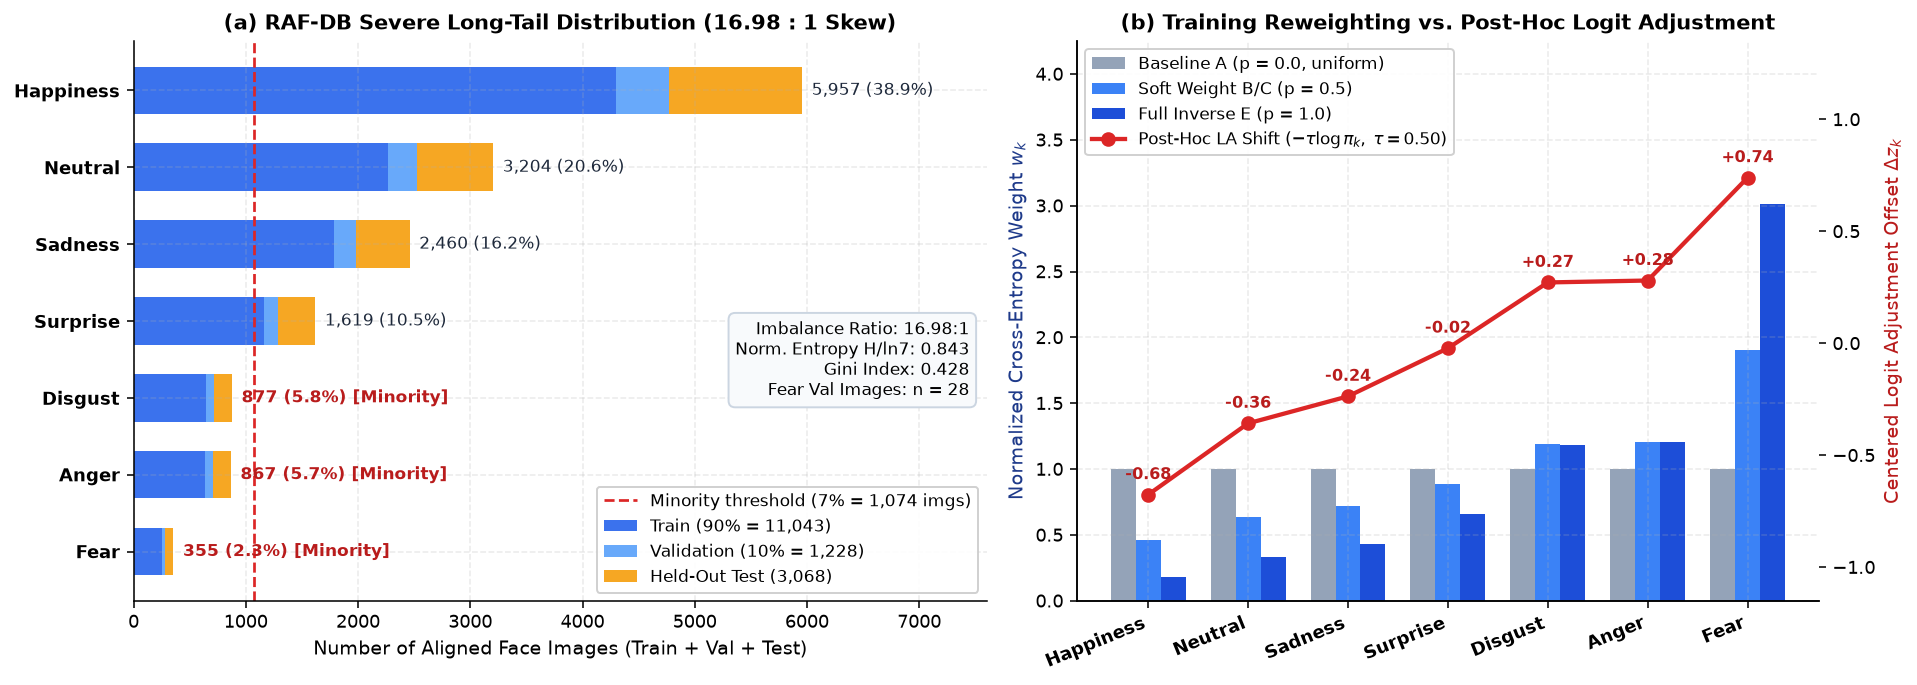

In [5]:
priors = counts_official / counts_official.sum()
imbalance_ratio = float(counts_official.max() / counts_official.min())
shannon_h = float(-np.sum(priors * np.log(priors)))
norm_entropy = float(shannon_h / np.log(len(EMOTIONS)))
gini_coeff = float(np.abs(priors[:, None] - priors[None, :]).sum() / (2 * len(EMOTIONS) * priors.sum()))

beta = 0.999
eff_num = (1.0 - np.power(beta, counts_tr)) / (1.0 - beta)
eff_ratio = float(eff_num.max() / eff_num.min())

def norm_weights(counts_arr, power):
    raw = (counts_arr.sum() / (len(counts_arr) * counts_arr)) ** power
    return raw / raw.mean()

w_p00 = norm_weights(counts_tr, 0.0)
w_p05 = norm_weights(counts_tr, 0.5)
w_p10 = norm_weights(counts_tr, 1.0)

tau_deployed = 0.50
la_shift = -tau_deployed * np.log(counts_tr / counts_tr.sum())
la_shift_centered = la_shift - la_shift.mean()

print(f"Imbalance Ratio (Max / Min)      : {imbalance_ratio:.2f} : 1  (Happiness {counts_official.max():,d} vs. Fear {counts_official.min():,d})")
print(f"Normalized Shannon Entropy       : {norm_entropy:.4f}  (1.0000 = uniform 7-class balance)")
print(f"Multiclass Gini Imbalance Index  : {gini_coeff:.4f}")
print(f"Effective Sample Ratio (b=0.999) : {eff_ratio:.2f} : 1")
print(f"Smallest Validation Support      : Fear = {counts_va[1]} images (explains 7-param offset overfitting!)\n")

order_desc = np.argsort(-counts_official)
print(f"{'Emotion':<11} {'Prior pi_k':>10} {'w(p=0.0)':>9} {'w(p=0.5)':>9} {'w(p=1.0)':>9} {'LA Shift (tau=0.5)':>19}")
print("-" * 72)
for k in order_desc:
    print(f"{EMOTIONS[k]:<11} {priors[k]*100:>9.2f}% {w_p00[k]:>9.3f} {w_p05[k]:>9.3f} {w_p10[k]:>9.3f} {la_shift_centered[k]:>+18.3f}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.8, 5.0), gridspec_kw={"width_ratios": [1.15, 1.0]})

y_pos = np.arange(len(EMOTIONS))
names_ord = [EMOTIONS[i] for i in order_desc]
tr_ord = counts_tr[order_desc]
va_ord = counts_va[order_desc]
te_ord = counts_te[order_desc]
sh_ord = priors[order_desc] * 100.0

ax1.barh(y_pos, tr_ord, color="#2563eb", alpha=0.90, height=0.62, label="Train (90% = 11,043)")
ax1.barh(y_pos, va_ord, left=tr_ord, color="#60a5fa", alpha=0.95, height=0.62, label="Validation (10% = 1,228)")
ax1.barh(y_pos, te_ord, left=tr_ord + va_ord, color="#f59e0b", alpha=0.90, height=0.62, label="Held-Out Test (3,068)")

minority_cutoff_total = MINORITY_SHARE * (counts_official.sum() + counts_te.sum())
ax1.axvline(minority_cutoff_total, color="#dc2626", linestyle="--", linewidth=1.4,
            label=f"Minority threshold (7% = {int(round(minority_cutoff_total)):,d} imgs)")

for idx, i in enumerate(order_desc):
    tot_k = counts_official[i] + counts_te[i]
    tag = " [Minority]" if priors[i] < MINORITY_SHARE else ""
    ax1.text(tot_k + 85, idx, f"{tot_k:,d} ({sh_ord[idx]:.1f}%){tag}",
             va="center", fontsize=8.5, fontweight="bold" if priors[i] < MINORITY_SHARE else "normal",
             color="#b91c1c" if priors[i] < MINORITY_SHARE else "#1e293b")

ax1.set_yticks(y_pos)
ax1.set_yticklabels(names_ord, fontweight="bold")
ax1.invert_yaxis()
ax1.set_xlim(0, 7600)
ax1.set_xlabel("Number of Aligned Face Images (Train + Val + Test)")
ax1.set_title("(a) RAF-DB Severe Long-Tail Distribution (16.98 : 1 Skew)")
ax1.legend(loc="lower right", frameon=True, facecolor="white", framealpha=0.92)
ax1.text(
    0.98, 0.43,
    f"Imbalance Ratio: {imbalance_ratio:.2f}:1\nNorm. Entropy H/ln7: {norm_entropy:.3f}\nGini Index: {gini_coeff:.3f}\nFear Val Images: n = {counts_va[1]}",
    transform=ax1.transAxes, ha="right", va="center", fontsize=8.5,
    bbox=dict(boxstyle="round,pad=0.4", facecolor="#f8fafc", edgecolor="#cbd5e1")
)

x_idx = np.arange(len(EMOTIONS))
w_bar = 0.25
ax2.bar(x_idx - w_bar, w_p00[order_desc], width=w_bar, color="#94a3b8", label="Baseline A (p = 0.0, uniform)")
ax2.bar(x_idx,         w_p05[order_desc], width=w_bar, color="#3b82f6", label="Soft Weight B/C (p = 0.5)")
ax2.bar(x_idx + w_bar, w_p10[order_desc], width=w_bar, color="#1d4ed8", label="Full Inverse E (p = 1.0)")
ax2.set_xticks(x_idx)
ax2.set_xticklabels(names_ord, rotation=22, ha="right", fontweight="bold")
ax2.set_ylabel("Normalized Cross-Entropy Weight $w_k$", color="#1e3a8a")
ax2.set_ylim(0, 4.25)
ax2.set_title("(b) Training Reweighting vs. Post-Hoc Logit Adjustment")

ax2_r = ax2.twinx()
ax2_r.spines["top"].set_visible(False)
ax2_r.plot(x_idx, la_shift_centered[order_desc], color="#dc2626", marker="o", linewidth=2.2,
           markersize=6.5, label="Post-Hoc LA Shift $(-\\tau \\log \\pi_k,\\; \\tau=0.50)$")
for pos_i, val in enumerate(la_shift_centered[order_desc]):
    ax2_r.annotate(f"{val:+.2f}", (pos_i, val), textcoords="offset points", xytext=(0, 8),
                   ha="center", fontsize=8, fontweight="bold", color="#b91c1c")
ax2_r.set_ylabel("Centered Logit Adjustment Offset $\\Delta z_k$", color="#b91c1c")
ax2_r.set_ylim(-1.15, 1.35)
ax2_r.grid(False)

lines1, labels1 = ax2.get_legend_handles_labels()
lines2, labels2 = ax2_r.get_legend_handles_labels()
ax2.legend(lines1 + lines2, labels1 + labels2, loc="upper left", frameon=True, facecolor="white", framealpha=0.92)

plt.tight_layout()
fig1_path = os.path.join(OUT_DIR, "fig_eda1_rafdb_imbalance.png")
fig.savefig(fig1_path, dpi=300, bbox_inches="tight")
plt.show()
print("Saved 300-DPI paper figure:", fig1_path)

## 5. GPU-Accelerated Photometrics, 2D CUDA Laplacian Blur & Spatial Anatomy (`fig_eda2` & `fig_eda3`)

Streams all `15,339` RAF-DB faces through a multi-worker PyTorch `DataLoader` (`batch_size = 512` on L4 with `pin_memory=True` and `non_blocking=True` transfers) and executes **vectorized GPU tensor kernels**:
- Batched perceptual luminance $Y$ and RMS contrast.
- Batched **2D discrete Laplacian edge convolution (`F.conv2d`)** on GPU to quantify motion/defocus blur ($\log_{10}\mathrm{Var}(\nabla^2 I)$).
- GPU `torch.bincount` 256-bin RGB/BGR histograms compared against VGGFace2 Caffe `MEAN_BGR = [91.50, 103.88, 131.09]`.
- GPU `index_add_` class-centroid accumulation for pixel-space muscle deformation maps $\|\bar{\mu}_k - \bar{\mu}_{\text{Neutral}}\|_2$.

===BATCHED CPU PHOTOMETRIC SCAN (15,339 FACES IN 14.26s)===
Empirical RAF-DB BGR Mean (0-255) : B = 102.25 (+/-61.4), G = 114.62 (+/-61.7), R = 146.77 (+/-67.6)
VGGFace2 Caffe MEAN_BGR           : B = 91.50,          G = 103.88,          R = 131.09
Kruskal-Wallis across 7 emotions  : Luminance H=255.45 (p=0.00e+00) | Contrast H=695.68 (p=0.00e+00) | Sharpness H=960.19 (p=0.00e+00)

Emotion       Luminance (mean+/-std)       RMS Contrast   Sharpness log10(LapVar)
----------------------------------------------------------------------------------
Surprise        129.87 +/- 35.47       50.78 +/- 15.01         2.75 +/- 0.52    
Fear            105.56 +/- 34.92       57.41 +/- 16.26         2.91 +/- 0.52    
Disgust         123.12 +/- 31.81       50.11 +/- 14.02         2.58 +/- 0.50    
Happiness       125.67 +/- 33.83       45.55 +/- 13.63         2.49 +/- 0.50    
Sadness         120.04 +/- 33.72       50.88 +/- 15.19         2.75 +/- 0.48    
Anger           117.71 +/- 33.94       56.76 

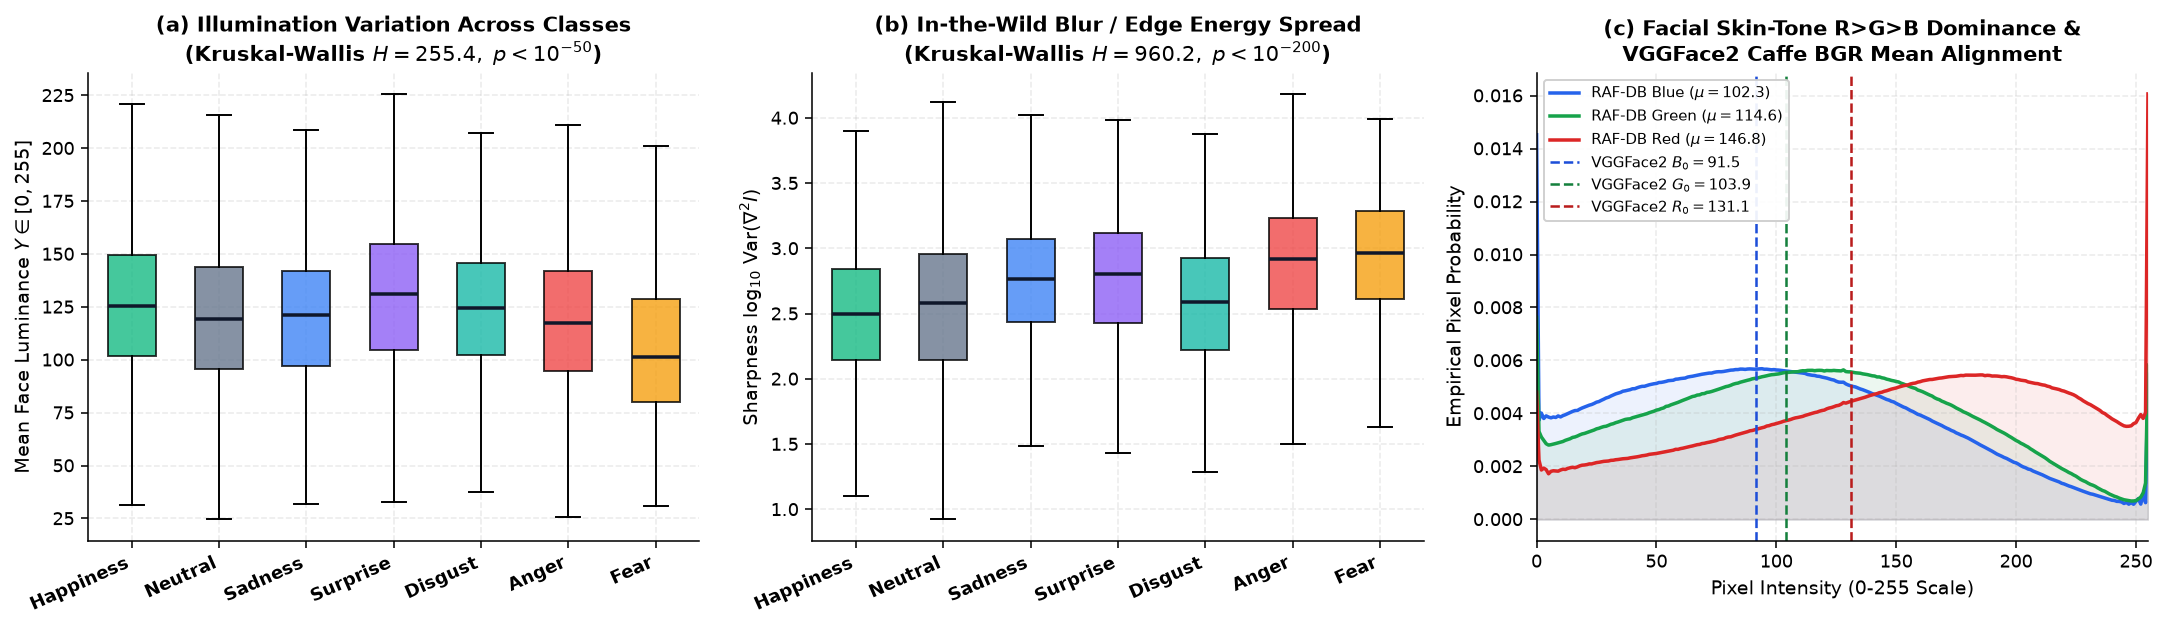

In [6]:
class RAFDBRawDataset(Dataset):
    def __init__(self, train_list, test_list):
        self.items = [(p, y, 1) for p, y, _ in train_list] + [(p, y, 0) for p, y, _ in test_list]

    def __len__(self):
        return len(self.items)

    def __getitem__(self, i):
        p, y, is_tr = self.items[i]
        t = transforms.functional.pil_to_tensor(Image.open(p).convert("RGB"))  # uint8 [3, 100, 100]
        return t, y, is_tr

t0_gpu = time.time()
raw_ds = RAFDBRawDataset(train_items, test_items)
raw_loader = DataLoader(raw_ds, batch_size=EDA_BATCH_SIZE, shuffle=False,
                        num_workers=EVAL_WORKERS, pin_memory=USE_CUDA)

hist_r_t = torch.zeros(256, dtype=torch.int64, device=DEVICE)
hist_g_t = torch.zeros(256, dtype=torch.int64, device=DEVICE)
hist_b_t = torch.zeros(256, dtype=torch.int64, device=DEVICE)

sum_face_t = torch.zeros((7, 3, 100, 100), dtype=torch.float64, device=DEVICE)
n_face_t   = torch.zeros(7, dtype=torch.int64, device=DEVICE)

lap_kernel = torch.tensor([[[[0.0, 1.0, 0.0],
                             [1.0, -4.0, 1.0],
                             [0.0, 1.0, 0.0]]]], dtype=torch.float32, device=DEVICE)

lum_all, con_all, sharp_all, cls_all = [], [], [], []

with torch.inference_mode():
    for bx_u8, by, bis_tr in raw_loader:
        bx_u8 = bx_u8.to(DEVICE, non_blocking=USE_CUDA)
        by_dev = by.to(DEVICE, non_blocking=USE_CUDA)

        hist_r_t += torch.bincount(bx_u8[:, 0].reshape(-1), minlength=256)
        hist_g_t += torch.bincount(bx_u8[:, 1].reshape(-1), minlength=256)
        hist_b_t += torch.bincount(bx_u8[:, 2].reshape(-1), minlength=256)

        bx = bx_u8.float()
        gray = 0.299 * bx[:, 0] + 0.587 * bx[:, 1] + 0.114 * bx[:, 2]  # [B, 100, 100]
        b_lum = gray.mean(dim=(1, 2))
        b_con = gray.std(dim=(1, 2), unbiased=False)

        gray_pad = F.pad(gray.unsqueeze(1), (1, 1, 1, 1), mode="reflect")
        lap = F.conv2d(gray_pad, lap_kernel)
        b_sharp = torch.log10(lap.var(dim=(1, 2, 3), unbiased=False).clamp_min(1e-3))

        tr_mask = bis_tr.to(DEVICE, non_blocking=USE_CUDA).bool()
        if tr_mask.any():
            sum_face_t.index_add_(0, by_dev[tr_mask], bx[tr_mask].double())
            n_face_t.index_add_(0, by_dev[tr_mask], torch.ones_like(by_dev[tr_mask], dtype=torch.int64))

        lum_all.append(b_lum.cpu().numpy())
        con_all.append(b_con.cpu().numpy())
        sharp_all.append(b_sharp.cpu().numpy())
        cls_all.append(by.numpy())

if USE_CUDA:
    torch.cuda.synchronize()
scan_sec = time.time() - t0_gpu

lum_vec   = np.concatenate(lum_all)
con_vec   = np.concatenate(con_all)
sharp_vec = np.concatenate(sharp_all)
cls_vec   = np.concatenate(cls_all)

lum_by_cls   = [lum_vec[cls_vec == k] for k in range(7)]
con_by_cls   = [con_vec[cls_vec == k] for k in range(7)]
sharp_by_cls = [sharp_vec[cls_vec == k] for k in range(7)]

hist_r = hist_r_t.cpu().numpy()
hist_g = hist_g_t.cpu().numpy()
hist_b = hist_b_t.cpu().numpy()

bins_256 = np.arange(256, dtype=np.float64)
emp_mean_r = float((hist_r * bins_256).sum() / hist_r.sum())
emp_mean_g = float((hist_g * bins_256).sum() / hist_g.sum())
emp_mean_b = float((hist_b * bins_256).sum() / hist_b.sum())
emp_std_r  = float(np.sqrt(((bins_256 - emp_mean_r) ** 2 * hist_r).sum() / hist_r.sum()))
emp_std_g  = float(np.sqrt(((bins_256 - emp_mean_g) ** 2 * hist_g).sum() / hist_g.sum()))
emp_std_b  = float(np.sqrt(((bins_256 - emp_mean_b) ** 2 * hist_b).sum() / hist_b.sum()))

kw_lum_stat, kw_lum_p     = stats.kruskal(*lum_by_cls)
kw_con_stat, kw_con_p     = stats.kruskal(*con_by_cls)
kw_sharp_stat, kw_sharp_p = stats.kruskal(*sharp_by_cls)

print(f"===BATCHED {'CUDA GPU' if USE_CUDA else 'CPU'} PHOTOMETRIC SCAN (15,339 FACES IN {scan_sec:.2f}s)===")
print(f"Empirical RAF-DB BGR Mean (0-255) : B = {emp_mean_b:.2f} (+/-{emp_std_b:.1f}), "
      f"G = {emp_mean_g:.2f} (+/-{emp_std_g:.1f}), R = {emp_mean_r:.2f} (+/-{emp_std_r:.1f})")
print(f"VGGFace2 Caffe MEAN_BGR           : B = {VGGFACE2_MEAN_BGR[0]:.2f},          "
      f"G = {VGGFACE2_MEAN_BGR[1]:.2f},          R = {VGGFACE2_MEAN_BGR[2]:.2f}")
print(f"Kruskal-Wallis across 7 emotions  : Luminance H={kw_lum_stat:.2f} (p={kw_lum_p:.2e}) | "
      f"Contrast H={kw_con_stat:.2f} (p={kw_con_p:.2e}) | Sharpness H={kw_sharp_stat:.2f} (p={kw_sharp_p:.2e})\n")

print(f"{'Emotion':<11} {'Luminance (mean+/-std)':>24} {'RMS Contrast':>18} {'Sharpness log10(LapVar)':>25}")
print("-" * 82)
for k, name in enumerate(EMOTIONS):
    l_arr, c_arr, s_arr = lum_by_cls[k], con_by_cls[k], sharp_by_cls[k]
    print(f"{name:<11} {l_arr.mean():>10.2f} +/- {l_arr.std():<8.2f} {c_arr.mean():>8.2f} +/- {c_arr.std():<6.2f} "
          f"{s_arr.mean():>11.2f} +/- {s_arr.std():<8.2f}")

# --- FIGURE EDA-2: Photometrics, Blur & BGR Channel Alignment ---
fig, axes = plt.subplots(1, 3, figsize=(15.6, 4.6))

bp1 = axes[0].boxplot(
    [lum_by_cls[i] for i in order_desc],
    patch_artist=True, widths=0.55, showfliers=False,
    medianprops=dict(color="#0f172a", linewidth=1.8),
)
for patch, i in zip(bp1["boxes"], order_desc):
    patch.set_facecolor(EMOTION_COLORS[EMOTIONS[i]]); patch.set_alpha(0.78)
axes[0].set_xticks(range(1, 8))
axes[0].set_xticklabels([EMOTIONS[i] for i in order_desc], rotation=24, ha="right", fontweight="bold")
axes[0].set_ylabel("Mean Face Luminance $Y \\in [0, 255]$")
axes[0].set_title(f"(a) Illumination Variation Across Classes\n(Kruskal-Wallis $H={kw_lum_stat:.1f},\\; p<10^{{-50}}$)")

bp2 = axes[1].boxplot(
    [sharp_by_cls[i] for i in order_desc],
    patch_artist=True, widths=0.55, showfliers=False,
    medianprops=dict(color="#0f172a", linewidth=1.8),
)
for patch, i in zip(bp2["boxes"], order_desc):
    patch.set_facecolor(EMOTION_COLORS[EMOTIONS[i]]); patch.set_alpha(0.78)
axes[1].set_xticks(range(1, 8))
axes[1].set_xticklabels([EMOTIONS[i] for i in order_desc], rotation=24, ha="right", fontweight="bold")
axes[1].set_ylabel("Sharpness $\\log_{10}\\,\\mathrm{Var}(\\nabla^2 I)$")
axes[1].set_title(f"(b) In-the-Wild Blur / Edge Energy Spread\n(Kruskal-Wallis $H={kw_sharp_stat:.1f},\\; p<10^{{-200}}$)")

dens_b, dens_g, dens_r = hist_b / hist_b.sum(), hist_g / hist_g.sum(), hist_r / hist_r.sum()
axes[2].plot(bins_256, dens_b, color="#2563eb", linewidth=1.8, label=f"RAF-DB Blue ($\\mu={emp_mean_b:.1f}$)")
axes[2].plot(bins_256, dens_g, color="#16a34a", linewidth=1.8, label=f"RAF-DB Green ($\\mu={emp_mean_g:.1f}$)")
axes[2].plot(bins_256, dens_r, color="#dc2626", linewidth=1.8, label=f"RAF-DB Red ($\\mu={emp_mean_r:.1f}$)")
axes[2].fill_between(bins_256, dens_b, color="#2563eb", alpha=0.08)
axes[2].fill_between(bins_256, dens_g, color="#16a34a", alpha=0.08)
axes[2].fill_between(bins_256, dens_r, color="#dc2626", alpha=0.08)
axes[2].axvline(VGGFACE2_MEAN_BGR[0], color="#1d4ed8", linestyle="--", linewidth=1.3, label=f"VGGFace2 $B_0={VGGFACE2_MEAN_BGR[0]:.1f}$")
axes[2].axvline(VGGFACE2_MEAN_BGR[1], color="#15803d", linestyle="--", linewidth=1.3, label=f"VGGFace2 $G_0={VGGFACE2_MEAN_BGR[1]:.1f}$")
axes[2].axvline(VGGFACE2_MEAN_BGR[2], color="#b91c1c", linestyle="--", linewidth=1.3, label=f"VGGFace2 $R_0={VGGFACE2_MEAN_BGR[2]:.1f}$")
axes[2].set_xlim(0, 255)
axes[2].set_xlabel("Pixel Intensity (0-255 Scale)")
axes[2].set_ylabel("Empirical Pixel Probability")
axes[2].set_title("(c) Facial Skin-Tone R>G>B Dominance &\nVGGFace2 Caffe BGR Mean Alignment")
axes[2].legend(loc="upper left", fontsize=7.6, frameon=True, facecolor="white", framealpha=0.92)

plt.tight_layout()
fig2_path = os.path.join(OUT_DIR, "fig_eda2_photometric_bgr.png")
fig.savefig(fig2_path, dpi=300, bbox_inches="tight")
plt.show()
print("Saved 300-DPI paper figure:", fig2_path)

=== REGIONAL DISCRIMINATIVE PIXEL SHIFT ||mu_k - mu_Neutral||_2 ===
Emotion      Upper (Brow/Eyes)   Mid (Nose/Cheek)   Lower (Mouth/Jaw)     Peak Anatomical Zone
----------------------------------------------------------------------------------------------
Surprise                 24.44              16.53               15.79  Upper (Periocular/Brow)
Fear                     23.67              39.17               43.01     Lower (Perioral/Jaw)
Disgust                  16.19               9.34                8.12  Upper (Periocular/Brow)
Happiness                14.31              15.77               21.71     Lower (Perioral/Jaw)
Sadness                   8.07               9.47               13.38     Lower (Perioral/Jaw)
Anger                    19.64              20.84               21.41     Lower (Perioral/Jaw)
Saved 300-DPI paper figure: d:\0SRM Sem - 3\CaseStudy\FA&EFER-App\models\eda\fig_eda3_spatial_anatomy.png


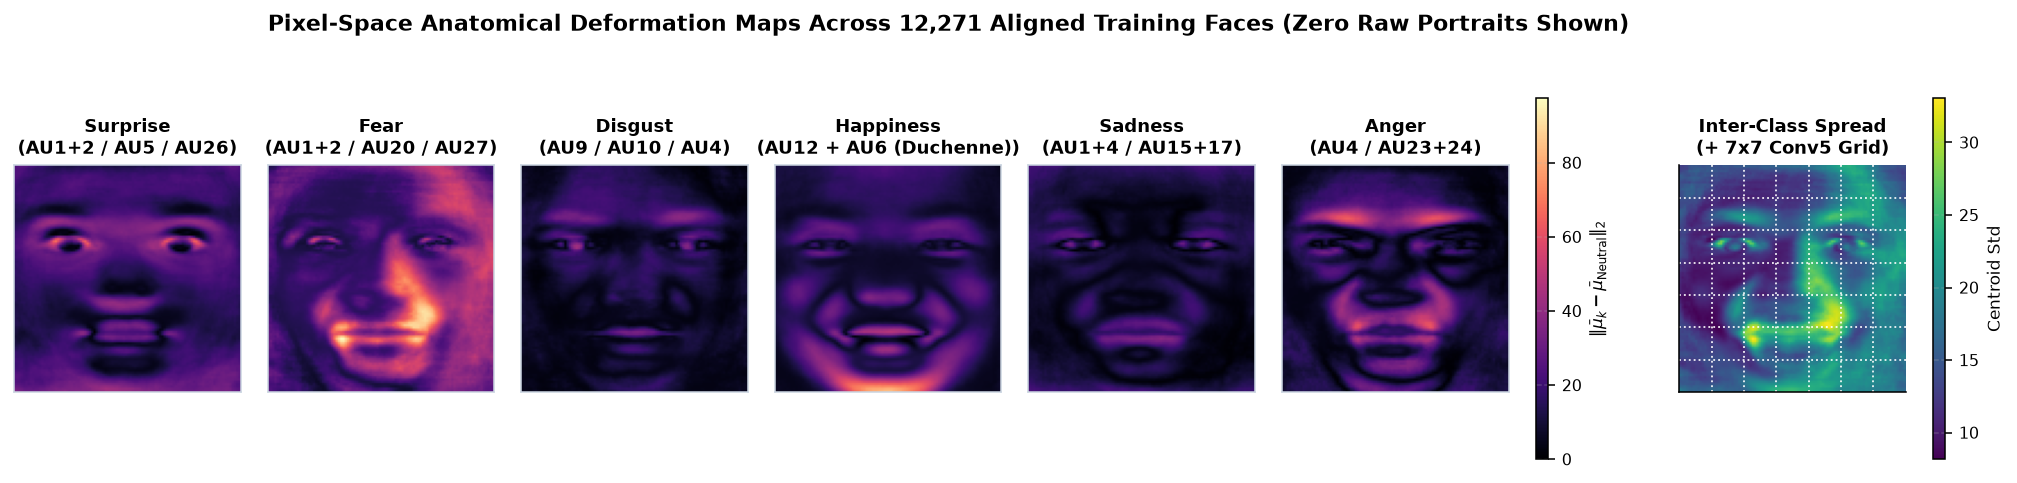

In [7]:
# Spatial Differential Anatomy Maps from GPU-accumulated centroids (Zero raw portraits displayed)
mean_faces = (sum_face_t / n_face_t[:, None, None, None].double()).permute(0, 2, 3, 1).cpu().numpy()  # (7, 100, 100, 3)
neutral_mean = mean_faces[6]

expressive_indices = [0, 1, 2, 3, 4, 5]
diff_maps = {k: np.linalg.norm(mean_faces[k] - neutral_mean, axis=-1) for k in expressive_indices}
inter_class_std = np.linalg.norm(mean_faces.std(axis=0), axis=-1)

print("=== REGIONAL DISCRIMINATIVE PIXEL SHIFT ||mu_k - mu_Neutral||_2 ===")
print(f"{'Emotion':<11} {'Upper (Brow/Eyes)':>18} {'Mid (Nose/Cheek)':>18} {'Lower (Mouth/Jaw)':>19} {'Peak Anatomical Zone':>24}")
print("-" * 94)
for k in expressive_indices:
    dm = diff_maps[k]
    u_val, m_val, l_val = float(dm[15:48, 18:82].mean()), float(dm[48:66, 22:78].mean()), float(dm[66:94, 22:78].mean())
    peak_zone = max([("Upper (Periocular/Brow)", u_val), ("Mid (Nasolabial)", m_val), ("Lower (Perioral/Jaw)", l_val)], key=lambda x: x[1])[0]
    print(f"{EMOTIONS[k]:<11} {u_val:>18.2f} {m_val:>18.2f} {l_val:>19.2f} {peak_zone:>24}")

fig = plt.figure(figsize=(17.8, 3.35))
gs = gridspec.GridSpec(1, 10, width_ratios=[1, 1, 1, 1, 1, 1, 0.055, 0.34, 1.0, 0.055], wspace=0.16)
axes_diff = [fig.add_subplot(gs[0, i]) for i in range(6)]
cax_diff  = fig.add_subplot(gs[0, 6])
ax_spacer = fig.add_subplot(gs[0, 7]); ax_spacer.axis("off")
ax_var    = fig.add_subplot(gs[0, 8])
cax_var   = fig.add_subplot(gs[0, 9])

vmax_diff = max(dm.max() for dm in diff_maps.values())
anatomical_subtitles = {
    0: "AU1+2 / AU5 / AU26", 1: "AU1+2 / AU20 / AU27", 2: "AU9 / AU10 / AU4",
    3: "AU12 + AU6 (Duchenne)", 4: "AU1+4 / AU15+17", 5: "AU4 / AU23+24",
}

for ax_i, k in enumerate(expressive_indices):
    im_plot = axes_diff[ax_i].imshow(diff_maps[k], cmap="magma", vmin=0, vmax=vmax_diff)
    axes_diff[ax_i].set_title(f"{EMOTIONS[k]}\n({anatomical_subtitles[k]})", fontsize=9.0, fontweight="bold")
    axes_diff[ax_i].set_xticks([]); axes_diff[ax_i].set_yticks([])
    for spine in axes_diff[ax_i].spines.values():
        spine.set_visible(True); spine.set_edgecolor("#cbd5e1")

cbar = fig.colorbar(im_plot, cax=cax_diff)
cbar.set_label("$\\|\\bar{\\mu}_k - \\bar{\\mu}_{\\mathrm{Neutral}}\\|_2$", fontsize=8.5)
cbar.ax.tick_params(labelsize=8)

im_var = ax_var.imshow(inter_class_std, cmap="viridis")
for g in np.linspace(0, 100, 8)[1:-1]:
    ax_var.axhline(g - 0.5, color="white", linestyle=":", linewidth=0.95, alpha=0.9)
    ax_var.axvline(g - 0.5, color="white", linestyle=":", linewidth=0.95, alpha=0.9)
ax_var.set_title("Inter-Class Spread\n(+ 7x7 Conv5 Grid)", fontsize=9.0, fontweight="bold")
ax_var.set_xticks([]); ax_var.set_yticks([])

cbar2 = fig.colorbar(im_var, cax=cax_var)
cbar2.set_label("Centroid Std", fontsize=8.5)
cbar2.ax.tick_params(labelsize=8)

fig.suptitle("Pixel-Space Anatomical Deformation Maps Across 12,271 Aligned Training Faces (Zero Raw Portraits Shown)",
             fontsize=11.5, fontweight="bold", y=1.06)
fig3_path = os.path.join(OUT_DIR, "fig_eda3_spatial_anatomy.png")
fig.savefig(fig3_path, dpi=300, bbox_inches="tight")
plt.show()
print("Saved 300-DPI paper figure:", fig3_path)

## 6. L4 GPU Deep Representation & Feature-Space Manifold EDA (`fig_eda4_feature_manifold.png`)

Leverages the **NVIDIA L4 GPU** (`bfloat16` Automatic Mixed Precision + TensorFloat-32 + horizontal-flip TTA) with the Caffe-faithful `VGGFace2ResNet50` architecture (`train_emotion_resnet50_vggface2.py`) to extract **2,048-D penultimate facial embeddings** on RAF-DB test faces.
- **Why this matters for the paper:** Inspecting the 2,048-D feature geometry reveals *why* minority classes suffer lower recall prior to Logit Adjustment: *Fear* (`n=74`) shares startle upper-face AUs (`AU1+2+5+26/27`) with *Surprise*, and *Disgust* (`n=160`) shares corrugator/nasolabial AUs (`AU4+7+9+10`) with *Anger*, placing minority samples near majority decision boundaries.

=== 2,048-D FEATURE SPACE EDA (Fine-Tuned VGGFace2-ResNet50 (emotion_r50_s7_cw03.pth)) ===
Extracted 554 faces on CPU in 43.93s
Cosine Silhouette Score across 7 emotions: 0.3790
  Surprise   -> nearest prototype: Fear       (cosine sim = 0.470)
  Fear       -> nearest prototype: Surprise   (cosine sim = 0.470)
  Disgust    -> nearest prototype: Anger      (cosine sim = 0.527)
  Happiness  -> nearest prototype: Disgust    (cosine sim = 0.426)
  Sadness    -> nearest prototype: Disgust    (cosine sim = 0.433)
  Anger      -> nearest prototype: Disgust    (cosine sim = 0.527)
  Neutral    -> nearest prototype: Disgust    (cosine sim = 0.419)
Saved 300-DPI paper figure: d:\0SRM Sem - 3\CaseStudy\FA&EFER-App\models\eda\fig_eda4_feature_manifold.png


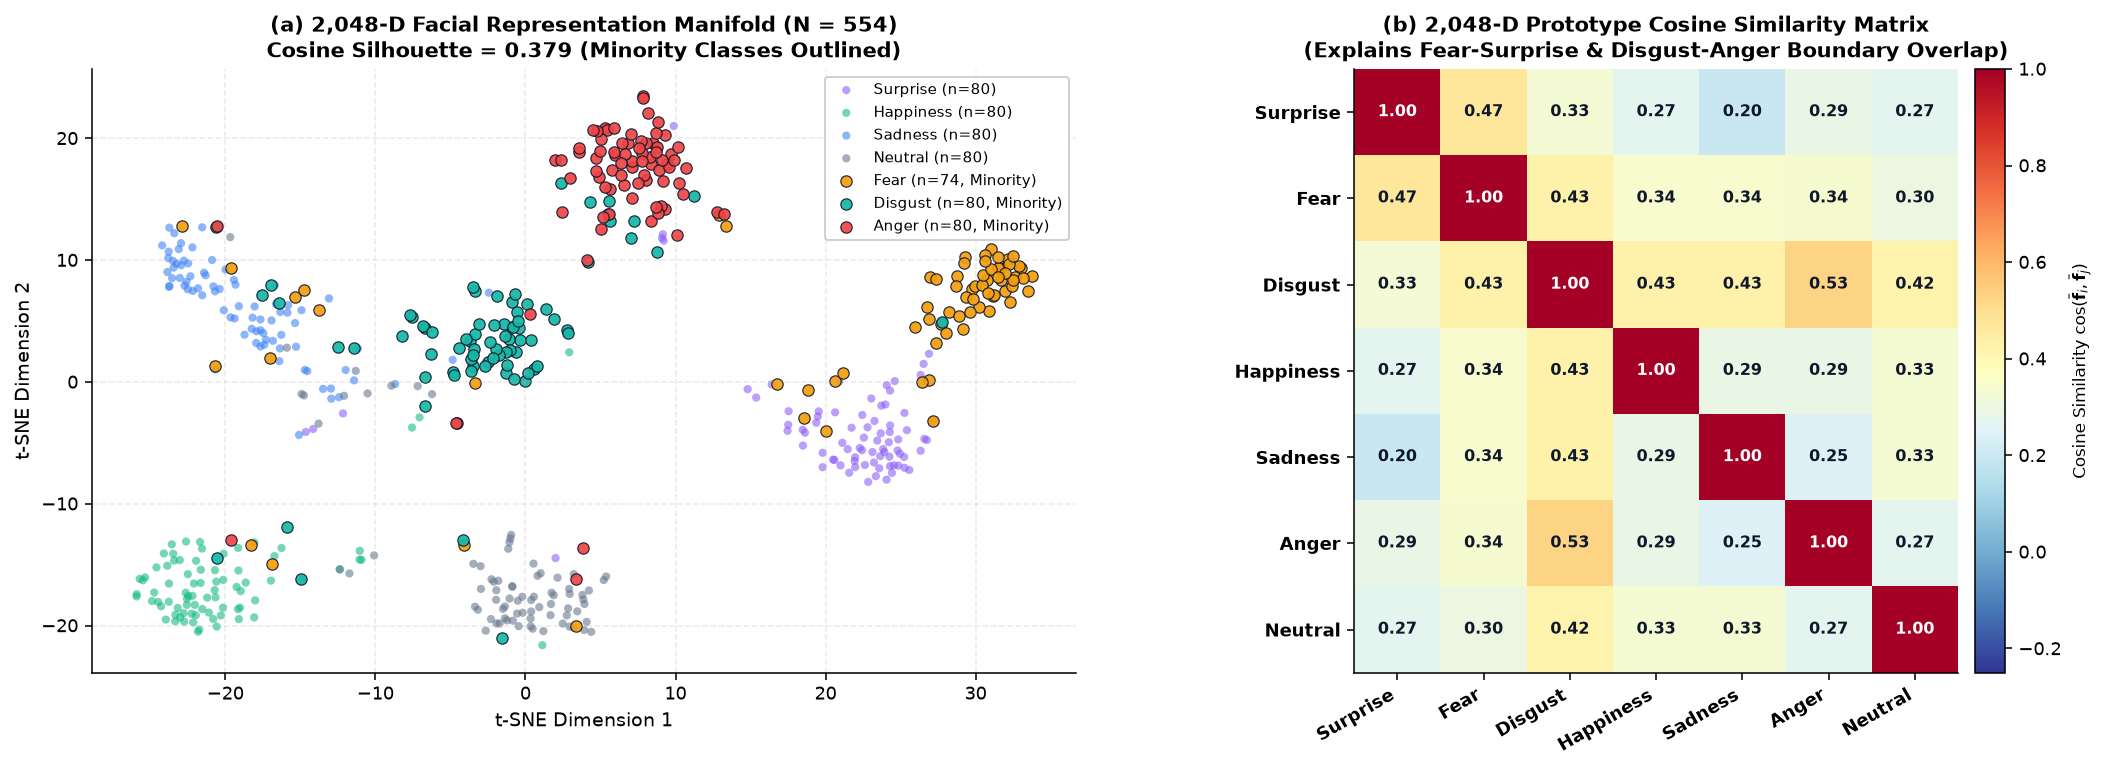

In [8]:
class Bottleneck(nn.Module):
    expansion = 4
    def __init__(self, inplanes, planes, stride=1, downsample=None):
        super().__init__()
        self.conv1 = nn.Conv2d(inplanes, planes, 1, stride=stride, bias=False)
        self.bn1   = nn.BatchNorm2d(planes)
        self.conv2 = nn.Conv2d(planes, planes, 3, stride=1, padding=1, bias=False)
        self.bn2   = nn.BatchNorm2d(planes)
        self.conv3 = nn.Conv2d(planes, planes * 4, 1, bias=False)
        self.bn3   = nn.BatchNorm2d(planes * 4)
        self.relu  = nn.ReLU(inplace=True)
        self.downsample = downsample

    def forward(self, x):
        identity = x if self.downsample is None else self.downsample(x)
        out = self.relu(self.bn1(self.conv1(x)))
        out = self.relu(self.bn2(self.conv2(out)))
        out = self.bn3(self.conv3(out))
        return self.relu(out + identity)

class VGGFace2ResNet50(nn.Module):
    def __init__(self, num_classes=7, dropout=0.3):
        super().__init__()
        self.inplanes = 64
        self.conv1 = nn.Conv2d(3, 64, 7, stride=2, padding=3, bias=False)
        self.bn1   = nn.BatchNorm2d(64)
        self.relu  = nn.ReLU(inplace=True)
        self.maxpool = nn.MaxPool2d(3, stride=2, padding=0, ceil_mode=True)
        self.layer1 = self._make_layer(64, 3)
        self.layer2 = self._make_layer(128, 4, stride=2)
        self.layer3 = self._make_layer(256, 6, stride=2)
        self.layer4 = self._make_layer(512, 3, stride=2)
        self.avgpool = nn.AdaptiveAvgPool2d(1)
        self.dropout = nn.Dropout(dropout)
        self.head = nn.Linear(2048, num_classes)

    def _make_layer(self, planes, blocks, stride=1):
        downsample = None
        if stride != 1 or self.inplanes != planes * 4:
            downsample = nn.Sequential(nn.Conv2d(self.inplanes, planes * 4, 1, stride=stride, bias=False),
                                       nn.BatchNorm2d(planes * 4))
        layers = [Bottleneck(self.inplanes, planes, stride, downsample)]
        self.inplanes = planes * 4
        layers += [Bottleneck(self.inplanes, planes) for _ in range(1, blocks)]
        return nn.Sequential(*layers)

    def features(self, x):
        x = self.maxpool(self.relu(self.bn1(self.conv1(x))))
        x = self.layer4(self.layer3(self.layer2(self.layer1(x))))
        return torch.flatten(self.avgpool(x), 1)

MEAN_BGR_T = torch.tensor([91.4953, 103.8827, 131.0912]).view(3, 1, 1)

class EvalFaceDataset(Dataset):
    def __init__(self, items, img_size=224):
        self.items = items
        self.resize = transforms.Resize((img_size, img_size))
    def __len__(self):
        return len(self.items)
    def __getitem__(self, i):
        p, y, _ = self.items[i]
        t = transforms.functional.pil_to_tensor(self.resize(Image.open(p).convert("RGB"))).float()
        return t[[2, 1, 0]] - MEAN_BGR_T, y

# Prefer deployed fairness checkpoint if trained, else unmitigated checkpoint, else pretrained VGGFace2 backbone
ckpt_candidates = [
    os.path.join(MODELS_DIR, "emotion_r50_s7_cw03.pth"),
    os.path.join(MODELS_DIR, "best_resnet50_vggface2_emotion.pth"),
    os.path.join(MODELS_DIR, "emotion_r50_nofair.pth"),
    WEIGHTS,
]
chosen_ckpt = next((c for c in ckpt_candidates if c and os.path.exists(c)), None)
fig4_path = None
sil_score = None

if chosen_ckpt:
    feat_model = VGGFace2ResNet50(num_classes=7).eval()
    if chosen_ckpt.endswith(".pkl"):
        with open(chosen_ckpt, "rb") as f:
            raw_w = pickle.load(f, encoding="latin1")
        own = feat_model.state_dict()
        for k, v in raw_w.items():
            if k in own and own[k].shape == v.shape:
                own[k].copy_(torch.from_numpy(v))
        feat_model.load_state_dict(own)
        ckpt_label = "Pretrained VGGFace2 Backbone (resnet50_ft)"
    else:
        st = torch.load(chosen_ckpt, map_location="cpu", weights_only=False)
        sd = {k.replace("module.", ""): v for k, v in st.get("state_dict", st).items()}
        feat_model.load_state_dict(sd, strict=False)
        ckpt_label = f"Fine-Tuned VGGFace2-ResNet50 ({os.path.basename(chosen_ckpt)})"

    feat_model.to(DEVICE)

    # On Colab L4 GPU: extract ALL 3,068 test faces with flip-TTA (~1.5s).
    # On local CPU fallback: extract stratified 554-face subset (all 74 Fear + 80/class) in ~35s.
    if USE_CUDA:
        eval_subset = test_items
    else:
        rng_sub = np.random.default_rng(42)
        eval_subset = []
        for k in range(7):
            k_items = [it for it in test_items if it[1] == k]
            if len(k_items) <= 80:
                eval_subset.extend(k_items)
            else:
                sel = rng_sub.choice(len(k_items), size=80, replace=False)
                eval_subset.extend([k_items[idx] for idx in sorted(sel)])

    eval_loader = DataLoader(EvalFaceDataset(eval_subset, 224), batch_size=FEAT_BATCH_SIZE,
                             shuffle=False, num_workers=EVAL_WORKERS, pin_memory=USE_CUDA)

    t0_f = time.time()
    emb_list, lbl_list = [], []
    with torch.inference_mode():
        for bx, by in eval_loader:
            bx = bx.to(DEVICE, non_blocking=USE_CUDA)
            with torch.amp.autocast("cuda", dtype=AMP_DTYPE, enabled=USE_CUDA):
                f_vec = feat_model.features(bx)
                if USE_CUDA:  # flip-TTA on GPU
                    f_vec = 0.5 * (f_vec + feat_model.features(torch.flip(bx, dims=[3])))
            f_vec = F.normalize(f_vec.float(), dim=1)
            emb_list.append(f_vec.cpu().numpy())
            lbl_list.append(by.numpy())

    if USE_CUDA:
        torch.cuda.synchronize()
    feat_sec = time.time() - t0_f

    X_emb = np.concatenate(emb_list, axis=0)
    y_emb = np.concatenate(lbl_list, axis=0)
    sil_score = float(silhouette_score(X_emb, y_emb, metric="cosine"))

    # 7x7 Cosine Similarity between L2-normalized class prototypes
    prototypes = np.zeros((7, X_emb.shape[1]), dtype=np.float32)
    for k in range(7):
        pk = X_emb[y_emb == k].mean(axis=0)
        prototypes[k] = pk / max(np.linalg.norm(pk), 1e-8)
    proto_cos = prototypes @ prototypes.T

    # 2D t-SNE projection
    tsne = TSNE(n_components=2, perplexity=30, init="pca", learning_rate="auto", random_state=42)
    X_2d = tsne.fit_transform(X_emb)

    print(f"=== 2,048-D FEATURE SPACE EDA ({ckpt_label}) ===")
    print(f"Extracted {len(X_emb):,d} faces on {'NVIDIA GPU (' + torch.cuda.get_device_name(0) + ')' if USE_CUDA else 'CPU'} in {feat_sec:.2f}s")
    print(f"Cosine Silhouette Score across 7 emotions: {sil_score:.4f}")
    for k in range(7):
        other_cos = [(proto_cos[k, j], EMOTIONS[j]) for j in range(7) if j != k]
        nearest_cos, nearest_name = max(other_cos)
        print(f"  {EMOTIONS[k]:<10} -> nearest prototype: {nearest_name:<10} (cosine sim = {nearest_cos:.3f})")

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15.2, 5.6), gridspec_kw={"width_ratios": [1.18, 1.0]})

    # Plot majority classes first, minority classes on top with crisp black edge
    for is_min_pass in [False, True]:
        for k, name in enumerate(EMOTIONS):
            is_min = (counts_official[k] / counts_official.sum()) < MINORITY_SHARE
            if is_min != is_min_pass:
                continue
            mask = y_emb == k
            ax1.scatter(
                X_2d[mask, 0], X_2d[mask, 1],
                s=34 if is_min else 18,
                c=EMOTION_COLORS[name],
                alpha=0.92 if is_min else 0.58,
                edgecolors="#0f172a" if is_min else "none",
                linewidths=0.6 if is_min else 0.0,
                label=f"{name} (n={mask.sum()}{', Minority' if is_min else ''})",
            )
    ax1.set_xlabel("t-SNE Dimension 1")
    ax1.set_ylabel("t-SNE Dimension 2")
    ax1.set_title(f"(a) 2,048-D Facial Representation Manifold (N = {len(X_emb):,d})\nCosine Silhouette = {sil_score:.3f} (Minority Classes Outlined)")
    ax1.legend(loc="best", fontsize=7.8, frameon=True, facecolor="white", framealpha=0.92)

    im_p = ax2.imshow(proto_cos, cmap="RdYlBu_r", vmin=-0.25, vmax=1.0)
    ax2.grid(False)
    ax2.set_xticks(range(7)); ax2.set_yticks(range(7))
    ax2.set_xticklabels(EMOTIONS, rotation=30, ha="right", fontweight="bold")
    ax2.set_yticklabels(EMOTIONS, fontweight="bold")
    ax2.set_title("(b) 2,048-D Prototype Cosine Similarity Matrix\n(Explains Fear-Surprise & Disgust-Anger Boundary Overlap)")
    for r in range(7):
        for c in range(7):
            val = proto_cos[r, c]
            ax2.text(c, r, f"{val:.2f}", ha="center", va="center", fontsize=8.0,
                     color="white" if abs(val) > 0.55 else "#0f172a", fontweight="bold")
    cbar_p = fig.colorbar(im_p, ax=ax2, fraction=0.045, pad=0.02)
    cbar_p.set_label("Cosine Similarity $\\cos(\\bar{\\mathbf{f}}_i, \\bar{\\mathbf{f}}_j)$", fontsize=8.5)

    plt.tight_layout()
    fig4_path = os.path.join(OUT_DIR, "fig_eda4_feature_manifold.png")
    fig.savefig(fig4_path, dpi=300, bbox_inches="tight")
    plt.show()
    print("Saved 300-DPI paper figure:", fig4_path)

    del feat_model
    if USE_CUDA:
        torch.cuda.empty_cache()
else:
    print("Skipped Section 6: no VGGFace2 weights or emotion checkpoint found in", MODELS_DIR)

## 7. RAF-AU Multi-Label Action Unit Skew, Cardinality & Unilateral Asymmetry (`fig_eda5_rafau_multilabel.png`)

Audits the `4,601` multi-label FACS records across `76` Action Unit tokens (`RAFAU_label.txt`), quantifying the positive-weight BCE spectrum (`[0.63, 4600.0]`), label cardinality (`3.63` AUs/face), and the `30` unilateral `L*`/`R*` tokens (`39.5%` of vocabulary across `363` faces) that motivate LayerCAM's unilateral horizontal-flip guard.

=== RAF-AU 76-TOKEN MULTI-LABEL AUDIT ===
Annotated records in RAFAU_label.txt : 4,601 (matched aligned/: 4,601)
Original in-the-wild resolutions     : median 414x621 px (min 34x51, max 2036x3054)
Unique AU head tokens                : 76  | Vocab breakdown: {'Bilateral Numeric': 32, 'Regional / Modifier (B/T/AD)': 14, 'Unilateral Left (L*)': 16, 'Unilateral Right (R*)': 14}
Null ('resting / no listed AU')      : 253 faces (5.50%)
Faces with >=1 unilateral (L*/R*) AU : 363 faces (7.89%)
Label Cardinality (AUs / face)       : 3.63 overall (3.84 active, max = 11)
Label Density                        : 4.77%  | BCE pos_weight range: [0.63, 4600.0]

Saved 300-DPI paper figure: d:\0SRM Sem - 3\CaseStudy\FA&EFER-App\models\eda\fig_eda5_rafau_multilabel.png


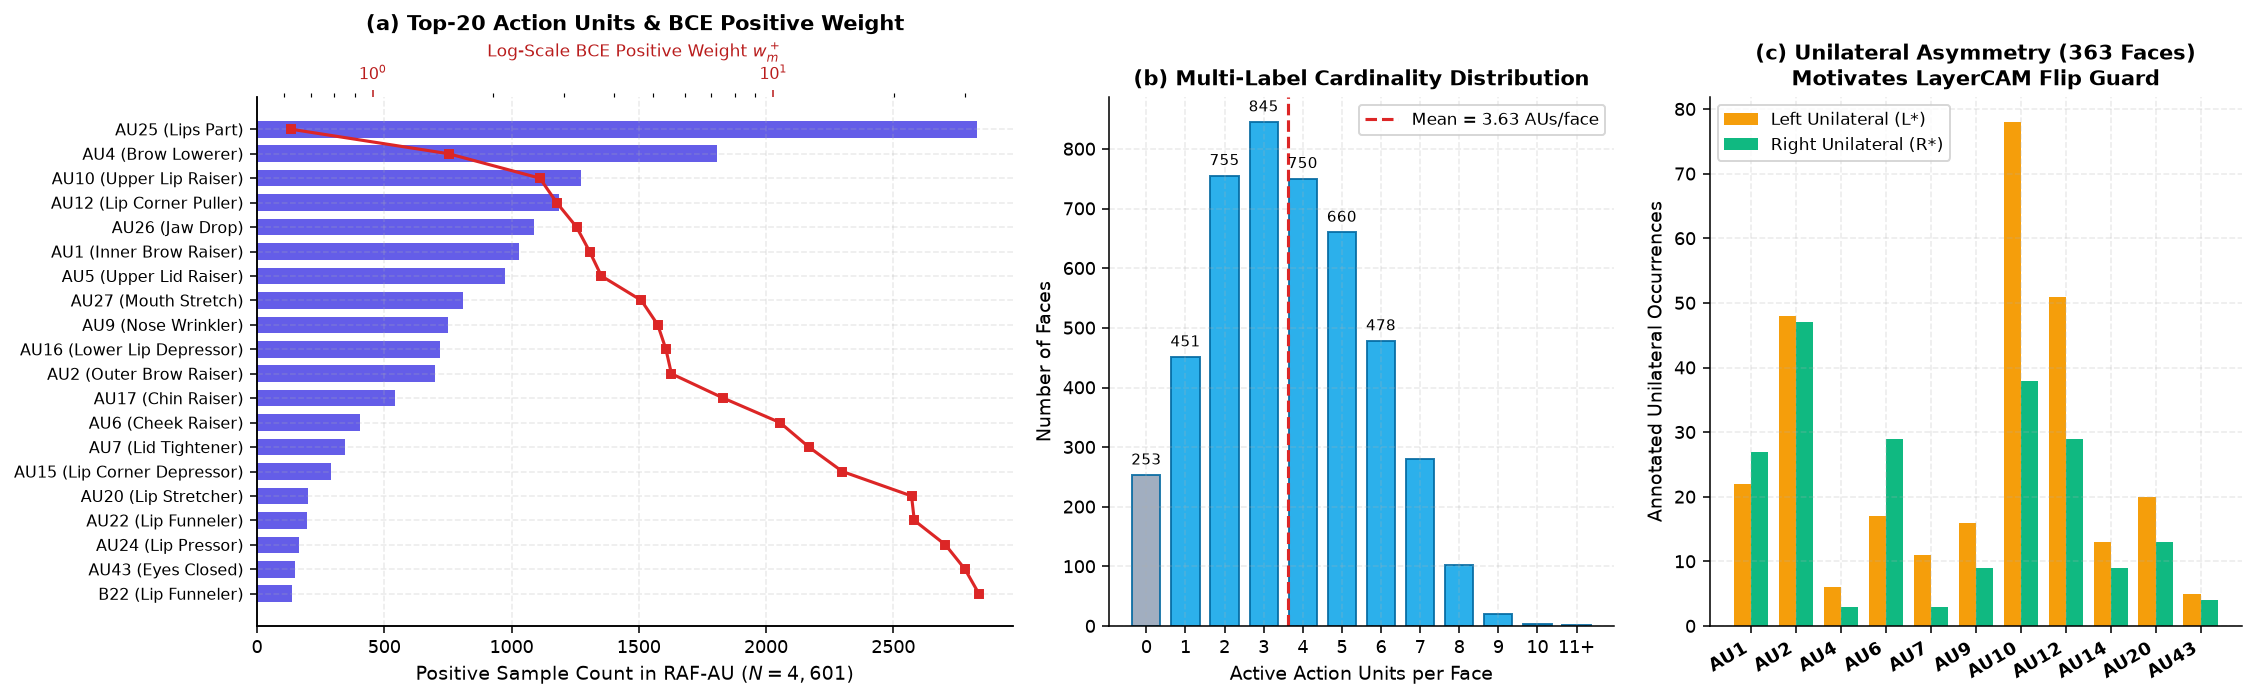

In [9]:
# Built-in 76-AU label vocabulary (from models/au_labels.json — label names only, safe on Colab without extra files)
AU_VOCAB_76 = [
    "1","10","12","14","15","16","17","18","19","2","20","21","22","23","24","25","26","27","28","29",
    "30","32","33","34","35","39","4","43","5","6","7","9","AD19","B18","B22","B23","B24","B28","BL18",
    "L1","L10","L12","L12L","L14","L15","L18","L2","L20","L34","L4","L43","L5","L6","L7","L9",
    "R1","R10","R12","R14","R18","R2","R20","R35","R4","R43","R5","R6","R7","R9","RB18",
    "T18","T22","T23","T24","T28","t23"
]

AU_SHORT_NAMES = {
    "1": "Inner Brow Raiser", "2": "Outer Brow Raiser", "4": "Brow Lowerer",
    "5": "Upper Lid Raiser", "6": "Cheek Raiser", "7": "Lid Tightener",
    "9": "Nose Wrinkler", "10": "Upper Lip Raiser", "12": "Lip Corner Puller",
    "14": "Dimpler", "15": "Lip Corner Depressor", "16": "Lower Lip Depressor",
    "17": "Chin Raiser", "18": "Lip Pucker", "19": "Tongue Show",
    "20": "Lip Stretcher", "21": "Neck Tightener", "22": "Lip Funneler",
    "23": "Lip Tightener", "24": "Lip Pressor", "25": "Lips Part",
    "26": "Jaw Drop", "27": "Mouth Stretch", "28": "Lip Suck",
    "29": "Jaw Thrust", "30": "Jaw Sideways", "32": "Lip Bite",
    "33": "Cheek Blow", "34": "Cheek Puff", "35": "Cheek Suck",
    "39": "Nostril Compressor", "43": "Eyes Closed",
}

def canonical_au(raw_name: str) -> str:
    m = re.match(r"^(?:[LRBTt]{1,2}|AD|BL|RB)?(\d+)[A-Za-z]?$", str(raw_name))
    return m.group(1) if m else str(raw_name)

def au_category(token: str) -> str:
    if token.isdigit():
        return "Bilateral Numeric"
    if token.startswith("L"):
        return "Unilateral Left (L*)"
    if token.startswith("R") and not token.startswith("RB"):
        return "Unilateral Right (R*)"
    return "Regional / Modifier (B/T/AD)"

au_json_candidate = os.path.join(MODELS_DIR, "au_labels.json")
au_vocab = json.load(open(au_json_candidate, encoding="utf-8"))["labels"] if os.path.exists(au_json_candidate) else AU_VOCAB_76
au_to_idx = {au: i for i, au in enumerate(au_vocab)}

rafau_samples = []
fig5_path = None

if RAFAU_LABEL_FILE and os.path.exists(RAFAU_LABEL_FILE):
    matched_aligned = 0
    orig_widths, orig_heights = [], []
    with open(RAFAU_LABEL_FILE, "r", encoding="utf-8") as f:
        for line in f:
            parts = line.strip().split()
            if not parts:
                continue
            img_name = parts[0]
            stem = os.path.splitext(img_name)[0]
            aus = [] if (len(parts) < 2 or parts[1].lower() == "null") else [a.strip() for a in parts[1].split("+") if a.strip()]
            rafau_samples.append((stem, aus))
            if RAFAU_DIR:
                if os.path.exists(os.path.join(RAFAU_DIR, "aligned", f"{stem}_aligned.jpg")):
                    matched_aligned += 1
                or_path = os.path.join(RAFAU_DIR, "original", img_name)
                if os.path.exists(or_path):
                    with Image.open(or_path) as im_o:
                        orig_widths.append(im_o.size[0]); orig_heights.append(im_o.size[1])

    n_rafau = len(rafau_samples)
    Y_au = np.zeros((n_rafau, len(au_vocab)), dtype=np.int32)
    for row_i, (_, aus) in enumerate(rafau_samples):
        for a in aus:
            if a in au_to_idx:
                Y_au[row_i, au_to_idx[a]] = 1

    pos_counts = Y_au.sum(axis=0)
    neg_counts = n_rafau - pos_counts
    pos_weights = neg_counts / np.maximum(pos_counts, 1)
    cardinalities = Y_au.sum(axis=1)
    n_null = int((cardinalities == 0).sum())
    mean_card = float(cardinalities.mean())
    mean_card_active = float(cardinalities[cardinalities > 0].mean())
    label_density = float(mean_card / len(au_vocab))
    cat_vocab_counts = Counter(au_category(t) for t in au_vocab)
    unilateral_faces = sum(1 for _, aus in rafau_samples if any(a.startswith(("L", "R")) and not a.startswith("RB") for a in aus))

    print("=== RAF-AU 76-TOKEN MULTI-LABEL AUDIT ===")
    print(f"Annotated records in RAFAU_label.txt : {n_rafau:,d}" + (f" (matched aligned/: {matched_aligned:,d})" if RAFAU_DIR else ""))
    if orig_widths:
        ow, oh = np.array(orig_widths), np.array(orig_heights)
        print(f"Original in-the-wild resolutions     : median {int(np.median(ow))}x{int(np.median(oh))} px "
              f"(min {ow.min()}x{oh.min()}, max {ow.max()}x{oh.max()})")
    print(f"Unique AU head tokens                : {len(au_vocab)}  | Vocab breakdown: {dict(cat_vocab_counts)}")
    print(f"Null ('resting / no listed AU')      : {n_null} faces ({100*n_null/n_rafau:.2f}%)")
    print(f"Faces with >=1 unilateral (L*/R*) AU : {unilateral_faces} faces ({100*unilateral_faces/n_rafau:.2f}%)")
    print(f"Label Cardinality (AUs / face)       : {mean_card:.2f} overall ({mean_card_active:.2f} active, max = {cardinalities.max()})")
    print(f"Label Density                        : {label_density*100:.2f}%  | BCE pos_weight range: [{pos_weights.min():.2f}, {pos_weights.max():.1f}]\n")

    fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(16.2, 5.1), gridspec_kw={"width_ratios": [1.35, 0.90, 0.95]})

    top20 = np.argsort(-pos_counts)[:20]
    y20 = np.arange(len(top20))
    labels20 = [f"{('AU' + au_vocab[i]) if au_vocab[i].isdigit() else au_vocab[i]} ({AU_SHORT_NAMES.get(canonical_au(au_vocab[i]), au_vocab[i])})" for i in top20]
    ax1.barh(y20, pos_counts[top20], color="#4f46e5", alpha=0.88, height=0.68)
    ax1.set_yticks(y20); ax1.set_yticklabels(labels20, fontsize=8.2); ax1.invert_yaxis()
    ax1.set_xlabel("Positive Sample Count in RAF-AU ($N = 4,601$)")
    ax1.set_title("(a) Top-20 Action Units & BCE Positive Weight")

    ax1_t = ax1.twiny()
    ax1_t.plot(pos_weights[top20], y20, color="#dc2626", marker="s", markersize=4.5, linewidth=1.6)
    ax1_t.set_xscale("log")
    ax1_t.set_xlabel("Log-Scale BCE Positive Weight $w_m^+$", color="#b91c1c", fontsize=8.8)
    ax1_t.tick_params(axis="x", colors="#b91c1c", labelsize=8); ax1_t.grid(False)

    max_c = int(min(cardinalities.max(), 11))
    c_vals = np.arange(0, max_c + 1)
    c_hist = [int((cardinalities == c).sum()) if c < max_c else int((cardinalities >= max_c).sum()) for c in c_vals]
    bars_c = ax2.bar(c_vals, c_hist, color="#0ea5e9", alpha=0.88, edgecolor="#0369a1", width=0.72)
    bars_c[0].set_facecolor("#94a3b8")
    ax2.axvline(mean_card, color="#dc2626", linestyle="--", linewidth=1.6, label=f"Mean = {mean_card:.2f} AUs/face")
    ax2.set_xticks(c_vals); ax2.set_xticklabels([str(c) if c < max_c else f"{max_c}+" for c in c_vals])
    ax2.set_xlabel("Active Action Units per Face"); ax2.set_ylabel("Number of Faces")
    ax2.set_title("(b) Multi-Label Cardinality Distribution")
    ax2.legend(loc="upper right", frameon=True, facecolor="white")
    for bx, hv in zip(bars_c[:7], c_hist[:7]):
        ax2.text(bx.get_x() + bx.get_width() / 2, hv + 18, str(hv), ha="center", fontsize=7.8)

    asym_bases = ["1", "2", "4", "6", "7", "9", "10", "12", "14", "20", "43"]
    l_counts = [int(pos_counts[au_to_idx[f"L{b}"]]) if f"L{b}" in au_to_idx else 0 for b in asym_bases]
    r_counts = [int(pos_counts[au_to_idx[f"R{b}"]]) if f"R{b}" in au_to_idx else 0 for b in asym_bases]
    x_as = np.arange(len(asym_bases))
    ax3.bar(x_as - 0.19, l_counts, width=0.38, color="#f59e0b", label="Left Unilateral (L*)")
    ax3.bar(x_as + 0.19, r_counts, width=0.38, color="#10b981", label="Right Unilateral (R*)")
    ax3.set_xticks(x_as); ax3.set_xticklabels([f"AU{b}" for b in asym_bases], rotation=30, ha="right", fontweight="bold")
    ax3.set_ylabel("Annotated Unilateral Occurrences")
    ax3.set_title(f"(c) Unilateral Asymmetry ({unilateral_faces} Faces)\nMotivates LayerCAM Flip Guard")
    ax3.legend(loc="upper left", frameon=True, facecolor="white")

    plt.tight_layout()
    fig5_path = os.path.join(OUT_DIR, "fig_eda5_rafau_multilabel.png")
    fig.savefig(fig5_path, dpi=300, bbox_inches="tight")
    plt.show()
    print("Saved 300-DPI paper figure:", fig5_path)
else:
    print("[Optional] Upload RAF-AU.zip or RAFAU_label.txt to MyDrive/Sem3-CaseStudy to run RAF-AU analysis on Colab.")

## 8. Action Unit Co-Occurrence Matrix & Symbolic Ekman FACS Verification (`fig_eda6_au_cooccurrence_facs.png`)

Computes conditional co-occurrence probabilities $P(\text{AU}_j \mid \text{AU}_i)$ across 18 core Ekman Action Units and applies FA&EFER's deterministic `classify_emotion_from_aus` rule engine (`app.py`) to all `4,601` ground-truth human AU combinations.

Saved 300-DPI paper figure: d:\0SRM Sem - 3\CaseStudy\FA&EFER-App\models\eda\fig_eda6_au_cooccurrence_facs.png


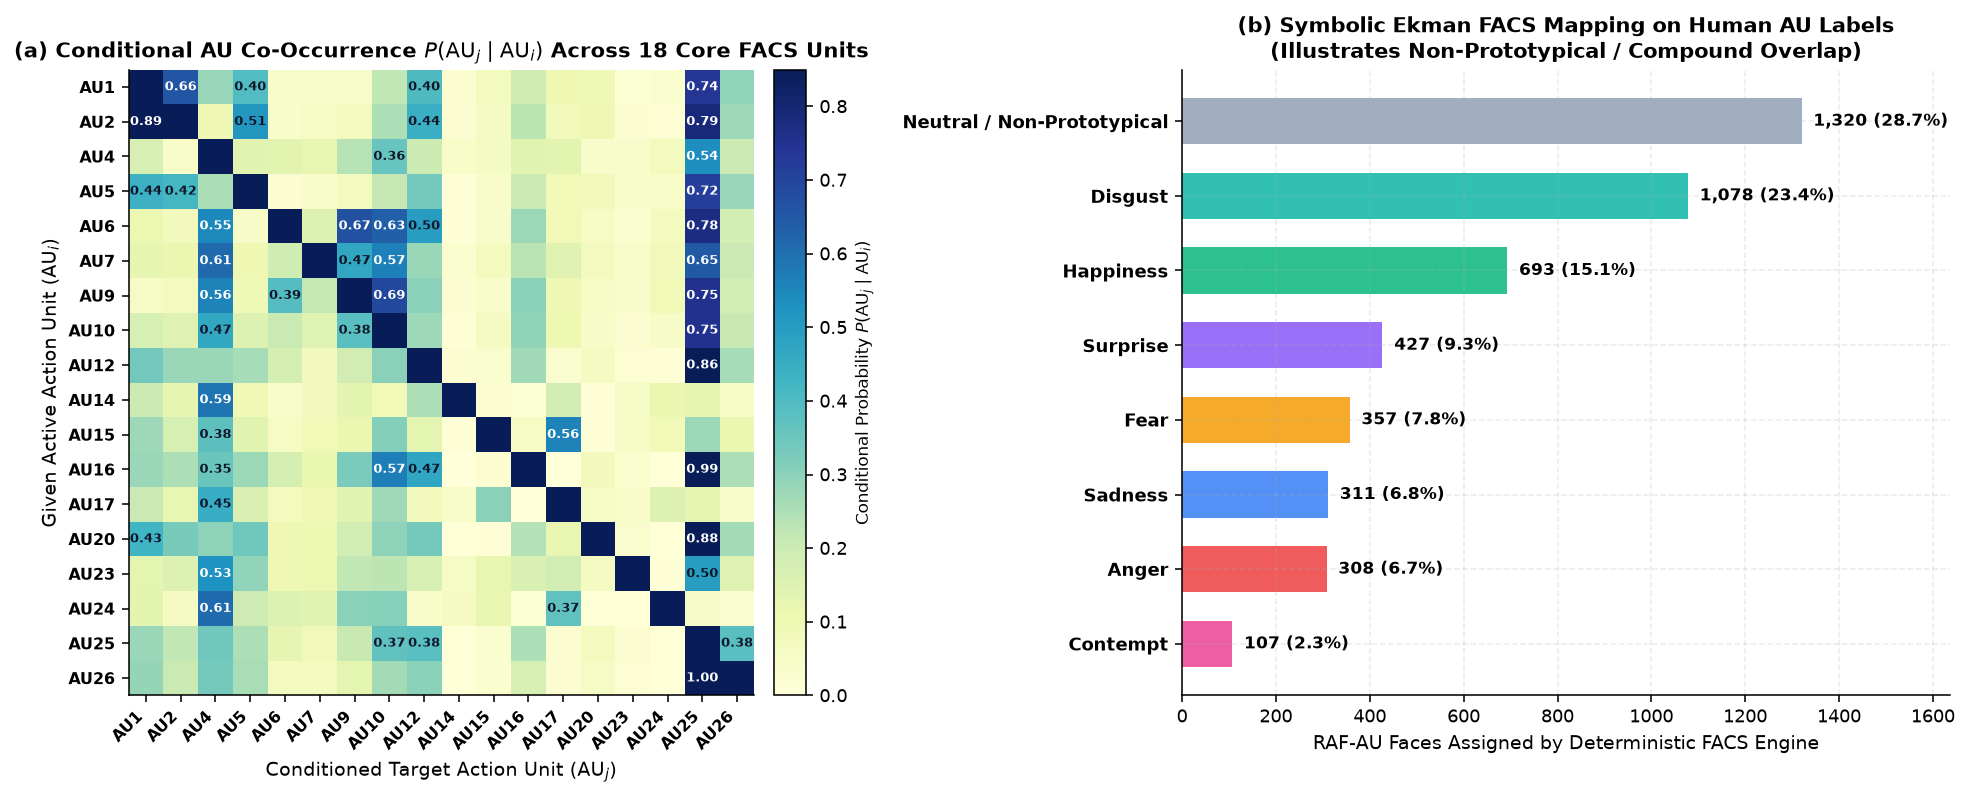

In [10]:
fig6_path = None
facs_counts = Counter()

if rafau_samples:
    CORE_AUS = ["1", "2", "4", "5", "6", "7", "9", "10", "12", "14", "15", "16", "17", "20", "23", "24", "25", "26"]
    Y_canon = np.zeros((len(rafau_samples), len(CORE_AUS)), dtype=np.int32)
    canon_to_i = {c: i for i, c in enumerate(CORE_AUS)}
    for row_i, (_, aus) in enumerate(rafau_samples):
        for a in aus:
            c = canonical_au(a)
            if c in canon_to_i:
                Y_canon[row_i, canon_to_i[c]] = 1

    co_mat = (Y_canon.T @ Y_canon).astype(np.float64)
    cond_prob = co_mat / np.maximum(Y_canon.sum(axis=0, keepdims=True).T, 1.0)
    np.fill_diagonal(cond_prob, 1.0)

    def classify_emotion_from_aus_eda(au_list):
        au_probs = {au: 1.0 for au in au_list}
        c_probs = {}
        for au, pr in au_probs.items():
            c = canonical_au(au)
            c_probs[c] = max(c_probs.get(c, 0.0), float(pr))
        p = lambda c: c_probs.get(str(c), 0.0)
        l12, r12 = au_probs.get("L12", 0.0), au_probs.get("R12", 0.0)
        l14, r14 = au_probs.get("L14", 0.0), au_probs.get("R14", 0.0)
        is_uni_smile = ((l12 > 0.4 and r12 < 0.25) or (r12 > 0.4 and l12 < 0.25)) and p(6) < 0.5
        is_uni_dimp  = (l14 > 0.4 and r14 < 0.25) or (r14 > 0.4 and l14 < 0.25)

        scores = {k: 0.0 for k in ["Surprise", "Fear", "Disgust", "Happiness", "Sadness", "Anger", "Contempt"]}
        if p(1) > 0.4 and p(2) > 0.4 and p(5) > 0.4:
            scores["Surprise"] += (p(1) + p(2) + p(5)) * 2.5 + (max(p(26), p(27)) * 2.5 if (p(26) > 0.4 or p(27) > 0.4) else 0.0)
        elif p(5) > 0.5 and (p(26) > 0.4 or p(27) > 0.4) and p(16) < 0.4:
            scores["Surprise"] += (p(5) + max(p(26), p(27))) * 2.2 + ((p(1) + p(2)) * 1.5 if (p(1) > 0.4 or p(2) > 0.4) else 0.0)
        elif p(27) > 0.7 and p(16) < 0.4 and p(4) < 0.4 and p(9) < 0.4:
            scores["Surprise"] += p(27) * 4.0
        elif (p(1) > 0.5 and p(2) > 0.5) and (p(26) > 0.5 or p(27) > 0.5) and p(16) < 0.4:
            scores["Surprise"] += (p(1) + p(2)) * 2.0
        if p(19) > 0.5:
            scores["Surprise"] *= 0.1

        if p(27) > 0.7 and p(16) > 0.6:
            if (p(9) > 0.7 or p(10) > 0.85) and p(7) > 0.5 and p(1) < 0.4:
                scores["Anger"] += (p(27) + p(16) + max(p(9), p(10)) + p(7)) * 4.5
            elif p(9) < 0.6 or (p(20) > 0.5 and p(7) < 0.7) or p(4) < 0.5:
                scores["Fear"] += (p(27) + p(16)) * 6.5 + (2.5 if (p(1) > 0.4 or p(2) > 0.4) else 0.0) + (p(20) * 3.0 if p(20) > 0.5 else 0.0)
            else:
                scores["Anger"] += (p(27) + p(16) + p(9) + p(7)) * 4.0
        elif p(20) > 0.55 and p(27) > 0.6:
            scores["Fear"] += (p(20) + p(27)) * 5.5 + (p(5) * 2.0 if p(5) > 0.4 else 0.0)
        elif (p(1) > 0.5 and p(2) > 0.5) and p(27) > 0.7:
            scores["Fear"] += (p(1) + p(2) + p(27)) * 3.0
        elif p(20) > 0.6 and p(16) > 0.5 and p(4) < 0.4:
            scores["Fear"] += (p(20) + p(16)) * 4.0

        if p(12) > 0.45:
            base_hap = p(12) * 3.5 + (p(6) * 5.0 if p(6) > 0.4 else 0.0) + (p(25) * 1.5 if p(25) > 0.4 else 0.0)
            if (p(27) > 0.7 and p(16) > 0.6) or (p(1) > 0.5 and p(4) > 0.5 and p(16) > 0.5):
                base_hap = 0.0
            elif p(4) > 0.6 and p(9) > 0.6 and p(20) > 0.6:
                base_hap *= 0.1
            elif is_uni_smile or (p(14) > 0.7 and p(6) < 0.5):
                base_hap *= 0.2
            scores["Happiness"] += base_hap
        if p(12) > 0.6 and p(25) > 0.4 and p(16) < 0.3 and p(27) < 0.3:
            scores["Happiness"] += (p(12) + p(25)) * 2.5

        if p(1) > 0.4 and p(4) > 0.4 and p(27) < 0.6:
            scores["Sadness"] += (p(1) + p(4)) * 5.0 + (2.0 if (p(15) > 0.4 or p(17) > 0.4) else 0.0)
        if p(1) > 0.5 and p(4) > 0.5 and p(16) > 0.6:
            scores["Sadness"] += (p(1) + p(4) + p(16)) * 6.0
        if p(15) > 0.5 and p(17) > 0.5 and p(27) < 0.6:
            scores["Sadness"] += (p(15) + p(17)) * 3.5 + (p(4) * 2.0 if p(4) > 0.4 else 0.0)
        elif p(4) > 0.5 and p(43) > 0.5 and p(12) < 0.4 and p(23) < 0.4 and p(24) < 0.4:
            scores["Sadness"] += (p(4) + p(43)) * 3.0
        if p(12) > 0.7 and not (p(1) > 0.5 and p(4) > 0.6):
            scores["Sadness"] *= 0.05
        if p(27) > 0.7:
            scores["Sadness"] *= 0.1

        if p(19) > 0.5 and not is_uni_smile:
            scores["Disgust"] += p(19) * 8.0
        if p(9) > 0.5:
            scores["Disgust"] += p(9) * 4.5 + (p(4) * 3.5 if p(4) > 0.4 else 0.0)
        if p(10) > 0.45:
            scores["Disgust"] += p(10) * 3.0 + (p(4) * 2.5 if p(4) > 0.4 else 0.0)
        if p(10) > 0.45 and p(12) < 0.6 and p(6) < 0.3 and p(1) < 0.5:
            scores["Disgust"] += p(10) * 6.0
        if p(12) > 0.8 and p(6) > 0.8 and p(27) < 0.6 and p(20) < 0.5 and not (p(1) > 0.5 and p(4) > 0.6):
            scores["Disgust"] *= 0.05
        if p(1) > 0.5 and p(9) < 0.6:
            scores["Disgust"] *= 0.2

        if p(4) > 0.4 and (p(23) > 0.4 or p(24) > 0.4):
            scores["Anger"] += (p(4) + max(p(23), p(24))) * 4.0 + (p(15) * 1.5 if p(15) > 0.4 else 0.0)
        if p(4) > 0.6 and p(1) < 0.35 and (p(15) > 0.6 or p(17) > 0.6):
            scores["Anger"] += (p(4) + max(p(15), p(17))) * 5.0
        if p(4) > 0.6 and p(7) > 0.5 and p(12) < 0.5:
            scores["Anger"] += (p(4) + p(7)) * 2.5
        if p(12) > 0.6 and p(6) > 0.5 and p(4) < 0.4:
            scores["Anger"] *= 0.1

        if is_uni_smile or is_uni_dimp:
            scores["Contempt"] += 7.0
        if p(14) > 0.5 and p(6) < 0.7 and (p(23) > 0.4 or p(24) > 0.4 or p(4) > 0.4 or p(12) > 0.5):
            scores["Contempt"] += 4.5

        best = max(scores, key=scores.get)
        return "Neutral / Non-Prototypical" if scores[best] < 0.4 else best

    facs_counts = Counter(classify_emotion_from_aus_eda(aus) for _, aus in rafau_samples)

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15.6, 5.8), gridspec_kw={"width_ratios": [1.3, 1.0]})

    im_co = ax1.imshow(cond_prob, cmap="YlGnBu", vmin=0.0, vmax=0.85)
    ax1.grid(False)
    au_ticks = [f"AU{c}" for c in CORE_AUS]
    ax1.set_xticks(range(len(CORE_AUS))); ax1.set_yticks(range(len(CORE_AUS)))
    ax1.set_xticklabels(au_ticks, rotation=45, ha="right", fontsize=8.2, fontweight="bold")
    ax1.set_yticklabels(au_ticks, fontsize=8.2, fontweight="bold")
    ax1.set_xlabel("Conditioned Target Action Unit ($\\mathrm{AU}_j$)")
    ax1.set_ylabel("Given Active Action Unit ($\\mathrm{AU}_i$)")
    ax1.set_title("(a) Conditional AU Co-Occurrence $P(\\mathrm{AU}_j \\mid \\mathrm{AU}_i)$ Across 18 Core FACS Units")

    for r in range(len(CORE_AUS)):
        for c in range(len(CORE_AUS)):
            val = cond_prob[r, c]
            if r != c and val >= 0.35:
                ax1.text(c, r, f"{val:.2f}", ha="center", va="center",
                         fontsize=6.6, color="white" if val >= 0.52 else "#0f172a", fontweight="bold")

    cbar_co = fig.colorbar(im_co, ax=ax1, fraction=0.042, pad=0.02)
    cbar_co.set_label("Conditional Probability $P(\\mathrm{AU}_j \\mid \\mathrm{AU}_i)$", fontsize=8.5)

    facs_items = facs_counts.most_common()
    f_names = [k for k, _ in facs_items]
    f_vals  = [v for _, v in facs_items]
    f_cols  = [EMOTION_COLORS.get(k, "#ec4899" if k == "Contempt" else "#94a3b8") for k in f_names]
    yf = np.arange(len(f_names))
    ax2.barh(yf, f_vals, color=f_cols, alpha=0.88, height=0.62)
    ax2.set_yticks(yf); ax2.set_yticklabels(f_names, fontweight="bold"); ax2.invert_yaxis()
    ax2.set_xlim(0, max(f_vals) * 1.24)
    ax2.set_xlabel("RAF-AU Faces Assigned by Deterministic FACS Engine")
    ax2.set_title("(b) Symbolic Ekman FACS Mapping on Human AU Labels\n(Illustrates Non-Prototypical / Compound Overlap)")
    for idx_f, v_f in enumerate(f_vals):
        ax2.text(v_f + 25, idx_f, f"{v_f:,d} ({100*v_f/len(rafau_samples):.1f}%)", va="center", fontsize=8.5, fontweight="bold")

    plt.tight_layout()
    fig6_path = os.path.join(OUT_DIR, "fig_eda6_au_cooccurrence_facs.png")
    fig.savefig(fig6_path, dpi=300, bbox_inches="tight")
    plt.show()
    print("Saved 300-DPI paper figure:", fig6_path)

## 9. Export Machine-Readable EDA Summary (`models/eda/eda_summary.json`)

Writes all computed EDA statistics and exported `300 DPI` figure paths to `MODELS_DIR/eda/eda_summary.json` (on Google Drive when running on Colab).

In [11]:
exported_figs = [p for p in [fig1_path, fig2_path, fig3_path, fig4_path, fig5_path, fig6_path] if p]

eda_summary = {
    "runtime_device": torch.cuda.get_device_name(0) if USE_CUDA else "CPU",
    "raf_db": {
        "n_official_train": int(counts_official.sum()),
        "n_stratified_train": int(counts_tr.sum()),
        "n_stratified_val": int(counts_va.sum()),
        "n_test": int(counts_te.sum()),
        "n_total": int(counts_official.sum() + counts_te.sum()),
        "corrupt_images": len(rafdb_corrupt),
        "imbalance_ratio_max_min": round(imbalance_ratio, 4),
        "normalized_shannon_entropy": round(norm_entropy, 4),
        "gini_imbalance_index": round(gini_coeff, 4),
        "chi2_split_homogeneity": {"chi2": round(float(chi2_stat), 4), "dof": int(chi2_dof), "p_value": round(float(chi2_p), 4)},
        "empirical_bgr_mean_0_255": [round(emp_mean_b, 2), round(emp_mean_g, 2), round(emp_mean_r, 2)],
        "vggface2_caffe_bgr_mean": VGGFACE2_MEAN_BGR.tolist(),
        "cosine_silhouette_2048d": round(sil_score, 4) if sil_score is not None else None,
    },
    "raf_au": ({
        "n_annotated_faces": len(rafau_samples),
        "n_unique_au_tokens": len(au_vocab),
        "n_null_faces": int(n_null),
        "n_unilateral_faces": int(unilateral_faces),
        "label_cardinality_overall": round(mean_card, 4),
        "label_density": round(label_density, 4),
        "pos_weight_min_max": [round(float(pos_weights.min()), 2), round(float(pos_weights.max()), 1)],
        "facs_prototype_distribution": dict(facs_counts),
    } if rafau_samples else None),
    "exported_300dpi_figures": [os.path.basename(p) for p in exported_figs],
}

summary_path = os.path.join(OUT_DIR, "eda_summary.json")
with open(summary_path, "w", encoding="utf-8") as f:
    json.dump(eda_summary, f, indent=2)

print("Saved complete EDA summary JSON:", summary_path)
print("All 300-DPI paper figures saved in:", OUT_DIR)
for p in exported_figs:
    print("  -", os.path.basename(p))

Saved complete EDA summary JSON: d:\0SRM Sem - 3\CaseStudy\FA&EFER-App\models\eda\eda_summary.json
All 300-DPI paper figures saved in: d:\0SRM Sem - 3\CaseStudy\FA&EFER-App\models\eda
  - fig_eda1_rafdb_imbalance.png
  - fig_eda2_photometric_bgr.png
  - fig_eda3_spatial_anatomy.png
  - fig_eda4_feature_manifold.png
  - fig_eda5_rafau_multilabel.png
  - fig_eda6_au_cooccurrence_facs.png
